Import Libraries

In [228]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

import sklearn
from sklearn.calibration import LabelEncoder
from  sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.decomposition import PCA
from xgboost import XGBClassifier

loading dataset

In [229]:
data = pd.read_csv('C:\\Users\\user\\Downloads\\INX_Future.csv')
data.head()

,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,...,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,...,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,...,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,...,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,...,4,10,1,3,2,2,2,2,No,3


After uploading, the files will be available in the current working directory of your Colab notebook (e.g., `/content/`). You can then load them using pandas as you tried to do before.

In [230]:
#check the data informations
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   EmpNumber                     1200 non-null   object
 1   Age                           1200 non-null   int64 
 2   Gender                        1200 non-null   object
 3   EducationBackground           1200 non-null   object
 4   MaritalStatus                 1200 non-null   object
 5   EmpDepartment                 1200 non-null   object
 6   EmpJobRole                    1200 non-null   object
 7   BusinessTravelFrequency       1200 non-null   object
 8   DistanceFromHome              1200 non-null   int64 
 9   EmpEducationLevel             1200 non-null   int64 
 10  EmpEnvironmentSatisfaction    1200 non-null   int64 
 11  EmpHourlyRate                 1200 non-null   int64 
 12  EmpJobInvolvement             1200 non-null   int64 
 13  EmpJobLevel       

there are two data types: Interger and Object

In [231]:
#checking the null calues
data.isnull().sum()

EmpNumber                       0
Age                             0
Gender                          0
EducationBackground             0
MaritalStatus                   0
EmpDepartment                   0
EmpJobRole                      0
BusinessTravelFrequency         0
DistanceFromHome                0
EmpEducationLevel               0
EmpEnvironmentSatisfaction      0
EmpHourlyRate                   0
EmpJobInvolvement               0
EmpJobLevel                     0
EmpJobSatisfaction              0
NumCompaniesWorked              0
OverTime                        0
EmpLastSalaryHikePercent        0
EmpRelationshipSatisfaction     0
TotalWorkExperienceInYears      0
TrainingTimesLastYear           0
EmpWorkLifeBalance              0
ExperienceYearsAtThisCompany    0
ExperienceYearsInCurrentRole    0
YearsSinceLastPromotion         0
YearsWithCurrManager            0
Attrition                       0
PerformanceRating               0
dtype: int64

there are no null values in the dataset

In [232]:
#checking the duplicates in the dataset
data.duplicated().sum()

np.int64(0)

there is no duplicates in the datasets

In [233]:
# decribtions of the data
data.describe()

,Age,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpHourlyRate,EmpJobInvolvement,EmpJobLevel,EmpJobSatisfaction,NumCompaniesWorked,EmpLastSalaryHikePercent,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,PerformanceRating
count,1200.000000,1200.000000,1200.00000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,36.918333,9.165833,2.89250,2.715833,65.981667,2.731667,2.067500,2.732500,2.665000,15.222500,2.725000,11.330000,2.785833,2.744167,7.077500,4.291667,2.194167,4.105000,2.948333
std,9.087289,8.176636,1.04412,1.090599,20.211302,0.707164,1.107836,1.100888,2.469384,3.625918,1.075642,7.797228,1.263446,0.699374,6.236899,3.613744,3.221560,3.541576,0.518866
min,18.000000,1.000000,1.00000,1.000000,30.000000,1.000000,1.000000,1.000000,0.000000,11.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000
25%,30.000000,2.000000,2.00000,2.000000,48.000000,2.000000,1.000000,2.000000,1.000000,12.000000,2.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000,3.000000
50%,36.000000,7.000000,3.00000,3.000000,66.000000,3.000000,2.000000,3.000000,2.000000,14.000000,3.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000,3.000000
75%,43.000000,14.000000,4.00000,4.000000,83.000000,3.000000,3.000000,4.000000,4.000000,18.000000,4.000000,15.000000,3.000000,3.000000,10.000000,7.000000,3.000000,7.000000,3.000000
max,60.000000,29.000000,5.00000,4.000000,100.000000,4.000000,5.000000,4.000000,9.000000,25.000000,4.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000,4.000000


In [234]:
#check the shapes
data.shape

(1200, 28)

There are 1200 samples and 28 featuers (variables)

EXPLONATORY DATA ANALYSIS

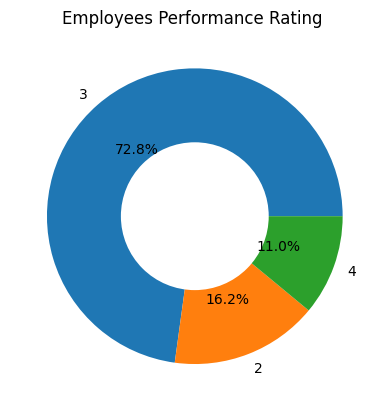

PerformanceRating
3    874
2    194
4    132
Name: count, dtype: int64


In [235]:
# target variable Employeee perfomance Rating
vals = data['PerformanceRating'].value_counts()
labels = vals.index # This will give you the variable names (ratings)
plt.pie(vals, labels=labels, autopct='%1.1f%%')
centre = plt.Circle((0,0),0.5,fc='white')
plt.gca().add_artist(centre)
plt.title('Employees Performance Rating ')
plt.show()

#target variable Employeee perfomance Rating
vals = data['PerformanceRating'].value_counts()
print (vals)

#The majority of the data, according to performance ratings, Excellent (72.8%), Good (16.2%), Outstanding (11.0%) respectively. Overall, most of the performance ratings fell within the excellent category.

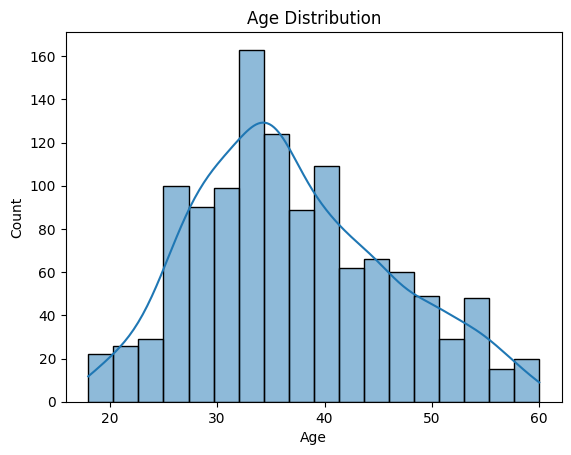

In [236]:
#Age Distributions
plt.figure()
sns.histplot(data['Age'], kde=True)
plt.title('Age Distribution')
plt.show()

##The majority of employees are concentrated in their early 30s, with around age 32 being the most common.
##Employee counts gradually decrease beyond the mid-30s, with fewer staff in their 40s, 50s, and approaching 60.
##Strong representation of younger employees may mean high potential for long-term growth

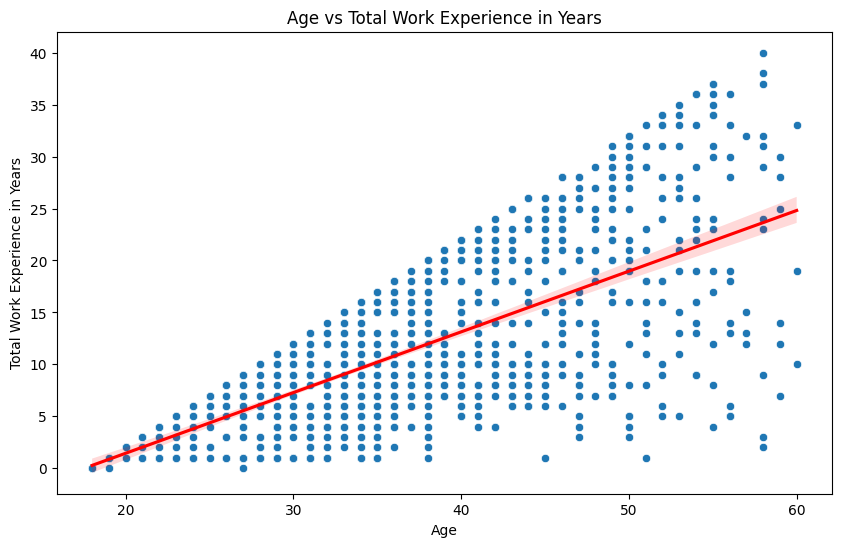

In [237]:
#Age vs years of experience
plt.figure(figsize=(10,6))
sns.scatterplot(x='Age', y='TotalWorkExperienceInYears', data=data)
sns.regplot(x='Age', y='TotalWorkExperienceInYears', data=data, scatter=False, color='red')  # Add a regression line
plt.xlabel('Age')
plt.ylabel('Total Work Experience in Years')
plt.title('Age vs Total Work Experience in Years')
plt.show()

There is a strong, linear relationship between Age and Total Work Experience. As age increases, the total years of work experience generally increase.

The workforce spans from roughly 18 to 60 years old.

Experience Variance: While the trend is upward, there is significant variance. 
For example, at age 50, some individuals have 30+ years of experience, while others have fewer than 5 years, likely indicating career changers or those who entered the workforce later.

While many employees have been in their current role for only 2–3 years, the scatter plot shows that many of these individuals are older and possess significantly higher total work experience (up to 40 years). This suggests the organization has a healthy mix of internal mobility and experienced external hires.

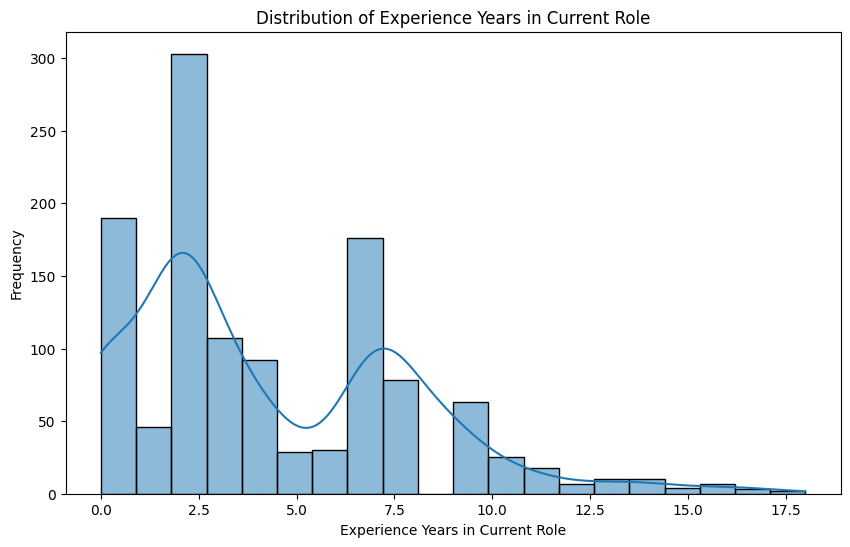

In [238]:
#ExperienceYearsInCurrentRole distributions 
plt.figure(figsize=(10,6))
sns.histplot(data['ExperienceYearsInCurrentRole'], kde=True)
plt.title('Distribution of Experience Years in Current Role')
plt.xlabel('Experience Years in Current Role')
plt.ylabel('Frequency')
plt.show()

Highest Density: The most significant cluster of employees falls between 2 and 3 years of experience. This specific bin reaches a frequency of over 300 employees, the highest in the entire dataset.

Implication: This suggests a period of heavy recruitment approximately two to three years ago or a high retention rate for those who have moved past the initial 1-year mark.

There is a clear "valley" around 5 years, suggesting that employees often leave the role or move internally before hitting their sixth year.

A second, smaller peak occurs around 7 to 8 years of experience. This group accounts for roughly 175 employees at its highest point.

These individuals represent the "institutional backbone" employees who have stayed long enough to gain deep expertise but haven't yet reached the "veteran" tail of the curve.

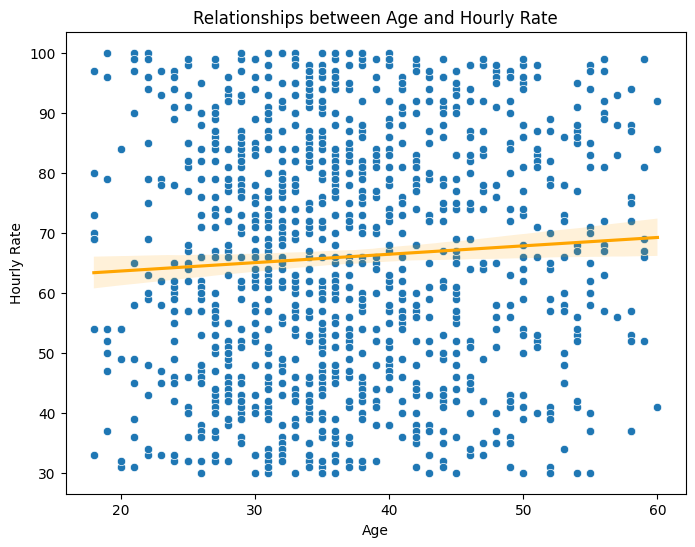

In [239]:
#Relationships between age and salary
plt.figure(figsize=(8,6))
sns.scatterplot(x='Age', y='EmpHourlyRate', data=data)
sns.regplot(x='Age', y='EmpHourlyRate', data=data, scatter=False, color='Orange')
plt.title('Relationships between Age and Hourly Rate')
plt.xlabel('Age')
plt.ylabel('Hourly Rate')
plt.show()

There is slightly relationship between the age and hourly work rate as shown above. there is slightly from roughly 64/hr at age 20 to $69/hr at age 60.

At almost every age point, pay ranges drastically from a floor of 30/hr to 100/hr.

This suggests that in this organization, pay is likely determined by role, performance, or specialized skills rather than simply by seniority or age.

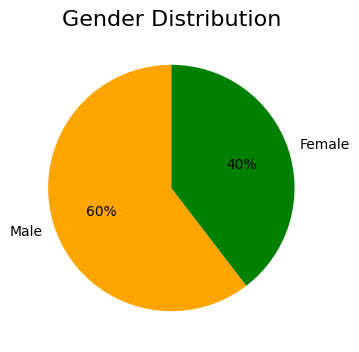

In [240]:
# Pie chart for Gender distribution
data['Gender'].value_counts().plot.pie(
    figsize=(4, 4),
    autopct='%1.0f%%', # show percentages
    colors=['orange', 'green'],  # vivid custom colors (Female, Male)
    startangle=90,            # start from top
)

plt.title('Gender Distribution', fontsize=16)
plt.ylabel('')  # remove default y-label for aesthetics
plt.show()



#According to the Gender, majority were male with 60% while Female at 40%. this suggest that majority employee are males

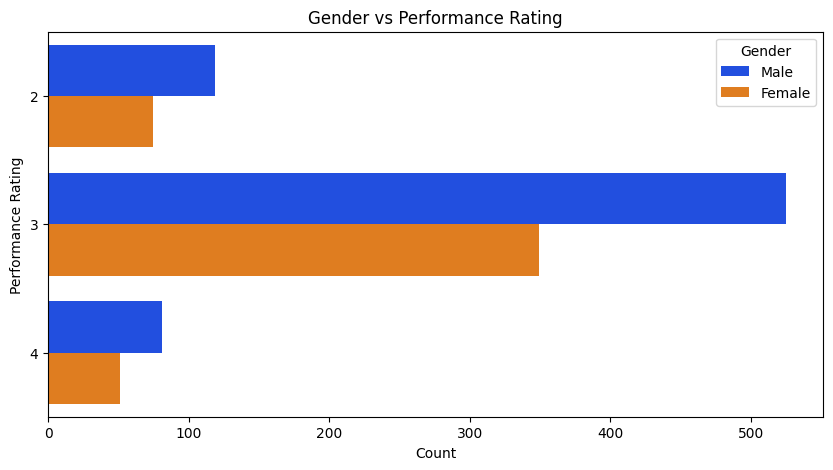

In [241]:
#Gender vs Perfomance chart
plt.figure(figsize=(10,5))
sns.countplot(y='PerformanceRating', hue='Gender', data=data, palette='bright')

plt.title('Gender vs Performance Rating')
plt.xlabel('Count')
plt.ylabel('Performance Rating')

plt.show()

##Majority perfoming according to the gender were male with many rated as excellent

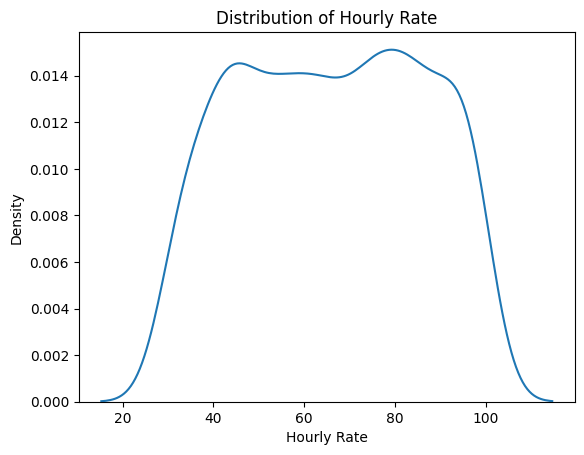

In [242]:
#KDE Plot
sns.kdeplot(data['EmpHourlyRate'])
plt.title('Distribution of Hourly Rate')
plt.xlabel('Hourly Rate')
plt.ylabel('Density')
plt.show()

##Majority employees eanerd their hourly rate between 40 and 90 per hour, since there is high

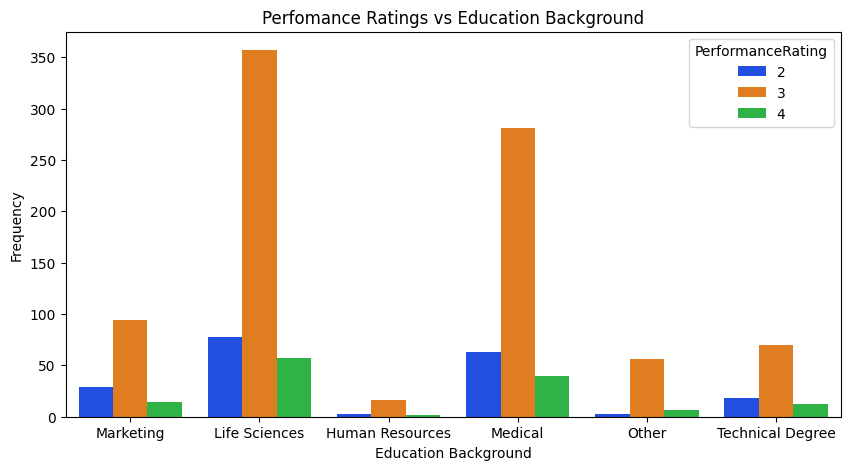

In [243]:
#performance rating vs education background
plt.figure(figsize=(10,5))
sns.countplot(x='EducationBackground',hue='PerformanceRating', data=data,  palette='bright')
plt.title('Perfomance Ratings vs Education Background')
plt.ylabel('Frequency')
plt.xlabel('Education Background')
plt.show()

##Life Sciences employees have the highest number of medium (rating 3) and high (rating 4) performers, making them the strongest group overall.


##Medical and Marketing backgrounds also show more employees in the medium rating (3), with fewer high performers (4).


##Human Resources and Other backgrounds have very few employees overall, mostly concentrated in rating 3.

##Technical Degree employees mostly fall in rating 3, with small numbers in ratings 2 and 4.




#Overall Insight

##Most employees across all education backgrounds are rated 3 (Excellent).

##High performance (rating 4) is concentrated in Life Sciences and Medical.

##Low performance (rating 2) is visible across Marketing, Medical, and Technical backgrounds, though less frequent.

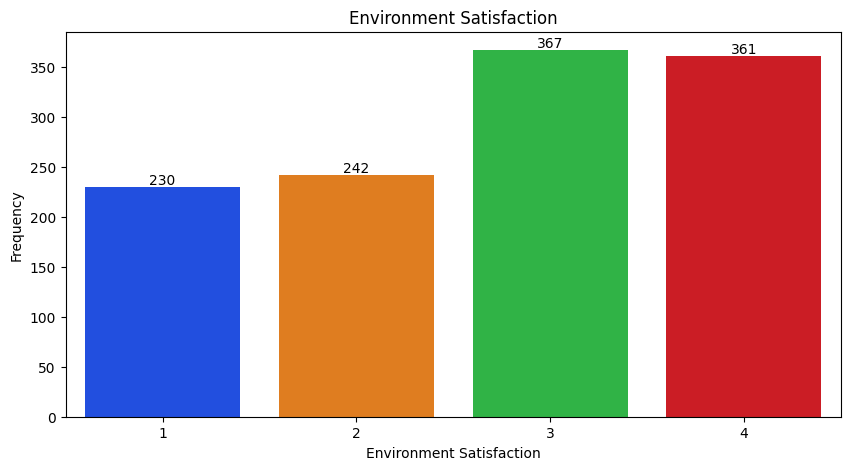

In [244]:
#Bar plot for EmpEnvironmentSatisfaction
plt.figure(figsize=(10,5))
ax=sns.countplot(x='EmpEnvironmentSatisfaction', data=data, palette='bright')
plt.title('Environment Satisfaction')
plt.ylabel('Frequency')
plt.xlabel('Environment Satisfaction')

for p in ax.containers:
    ax.bar_label(p)

plt.show()

##Most employees are satisfied with the environment, with high (3) and very high (4) satisfaction accounting for the majority (~728 employees).

##Only a smaller portion of employees report low or medium satisfaction (~472 employees combined).

##This suggests that overall workplace environment is positively perceived, which could be leveraged to improve performance and morale.

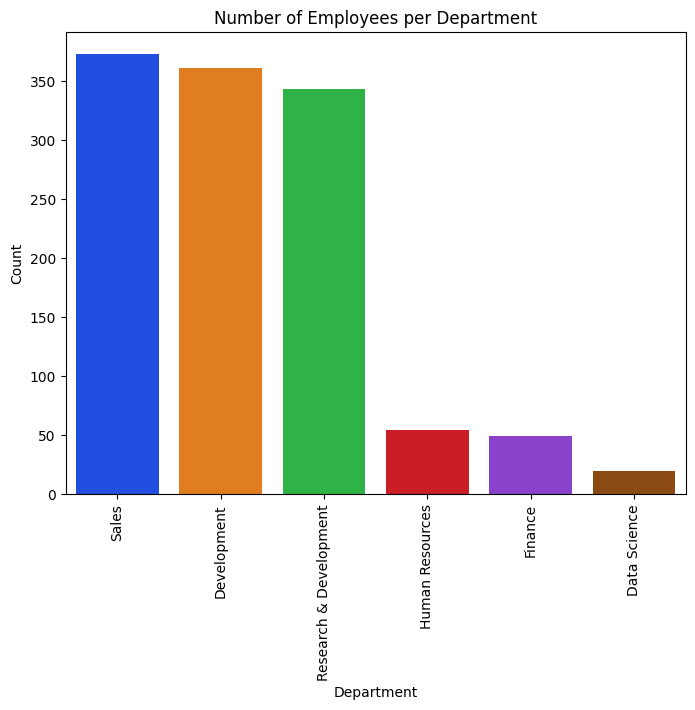

In [245]:
#EmpDepartment
plt.figure(figsize=(8,6))
dept_order = data['EmpDepartment'].value_counts().index

sns.countplot(x='EmpDepartment',data=data,order=dept_order,palette='bright')
plt.title('Number of Employees per Department')
plt.ylabel('Count')
plt.xlabel('Department')
plt.xticks(rotation=90)

plt.show()

##the employee distribution shows that the organization’s workforce is heavily concentrated in Sales, Development, and Research & Development, indicating a strong focus on revenue generation and product innovation. In contrast, support and analytical departments such as Human Resources, Finance, and Data Science have significantly fewer employees, suggesting a lean structure in administrative and data-focused functions.

##The company appears to prioritize sales performance and product development, with lean staffing in administrative and analytical functions

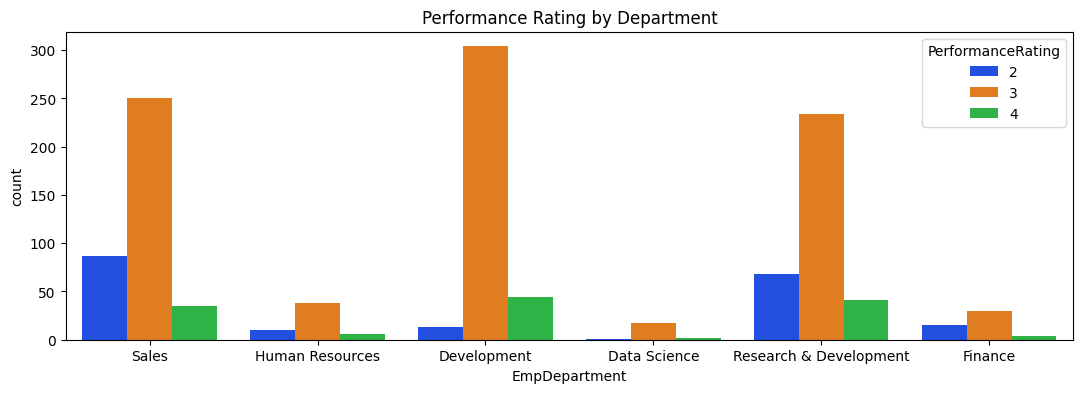

In [246]:
#Perfomance Rating by Departments
plt.figure(figsize=(13,4))
sns.countplot(x='EmpDepartment', hue='PerformanceRating', data=data, palette='bright')
plt.title('Performance Rating by Department')
plt.show()

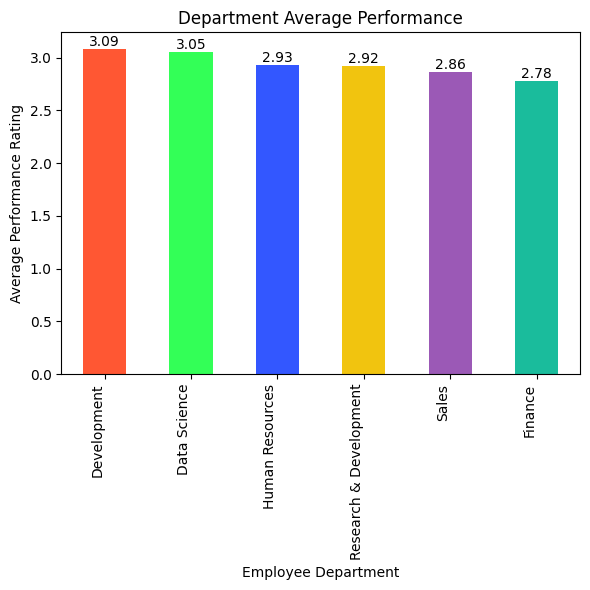

In [247]:
# Department Average Performance
vals = data.groupby('EmpDepartment')['PerformanceRating'].mean()
vals = vals.sort_values(ascending=False)

plt.figure(figsize=(6, 6))
ax=vals.plot.bar(color=['#FF5733', '#33FF57', '#3357FF', '#F1C40F', '#9B59B6', '#1ABC9C'])
plt.title("Department Average Performance")
plt.ylabel("Average Performance Rating")
plt.xlabel("Employee Department")
plt.xticks(rotation=90, ha='right')
plt.tight_layout()

for p in ax.containers:
    ax.bar_label(p, fmt='%.2f')
plt.show()

###The differences across departments are relatively small, with only a 0.3 spread between the highest and lowest performers.

###Development and Data Science are slightly ahead, suggesting stronger performance consistency.

###Finance may need targeted support or interventions to raise its average closer to the organizational benchmark.

##The clustering of HR and R&D at 2.9 indicates similar performance challenges or comparable evaluation standards.

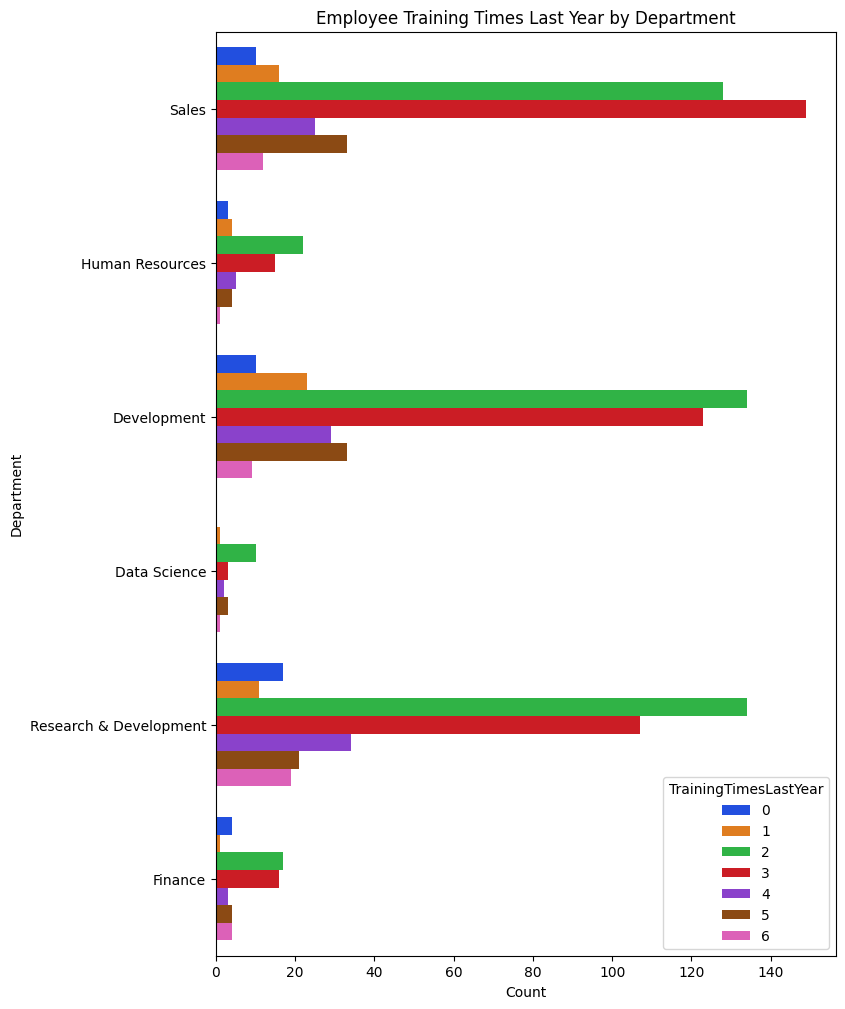

In [248]:
#TrainingTimesLastYear per department
plt.figure(figsize=(8,12))
sns.countplot(y='EmpDepartment', hue='TrainingTimesLastYear', data=data, palette='bright')
plt.title('Employee Training Times Last Year by Department')
plt.xlabel('Count')
plt.ylabel('Department')
plt.show()

Sales department- Majority employees were trained 3 times and 2 times last year
Development and Research Development, the hishest number of trained employees were those who trained 2 times, followed by the 2 times 
Human Resource, Data science and Finance few attended trainings, therefore majority still follows 2 times and 3 times trainings 

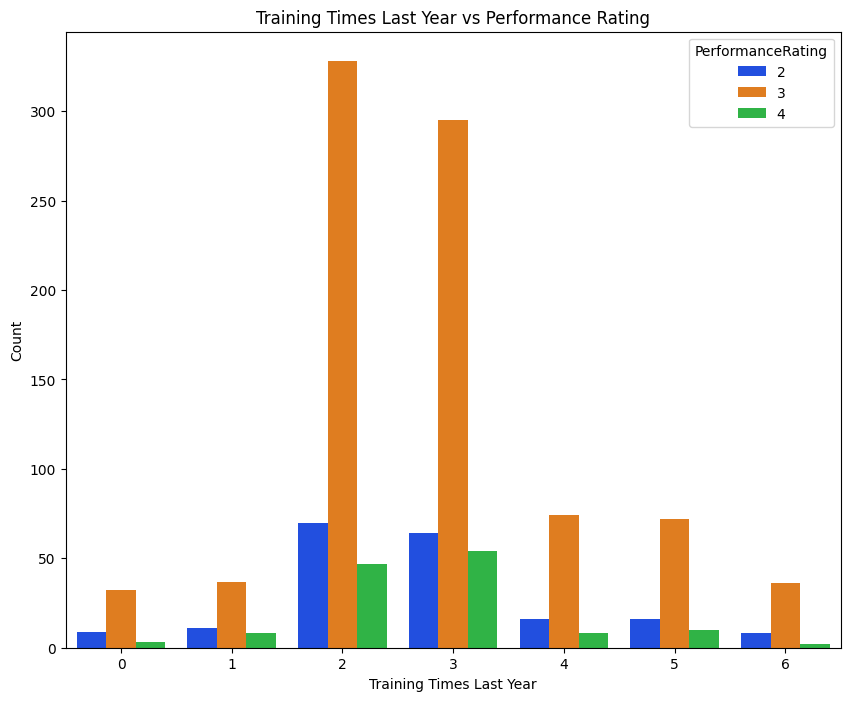

In [249]:
#TrainingTimesLastYear by perfomance ratings
plt.figure(figsize=(10,8))
sns.countplot(x='TrainingTimesLastYear', hue='PerformanceRating', data=data, palette='bright')
plt.title('Training Times Last Year vs Performance Rating')
plt.ylabel('Count')
plt.xlabel('Training Times Last Year')
plt.show()



The highest counts are at 2 and 3 training sessions.
Employees with Performance Rating 4 appear mostly among those trained 2–3 times.
Very few employees with 0 or 6 trainings achieve rating 4.
For every number of training sessions (0–6), Rating 3 has the highest count.
This suggests the organization has a large proportion of average performers.

There appears to be a moderate positive relationship between training frequency (especially 2–3 sessions) and better performance ratings. However: Increasing training beyond 3 sessions (4–6) does not clearly increase high performance (rating 4).

The relationship is not strongly linear.

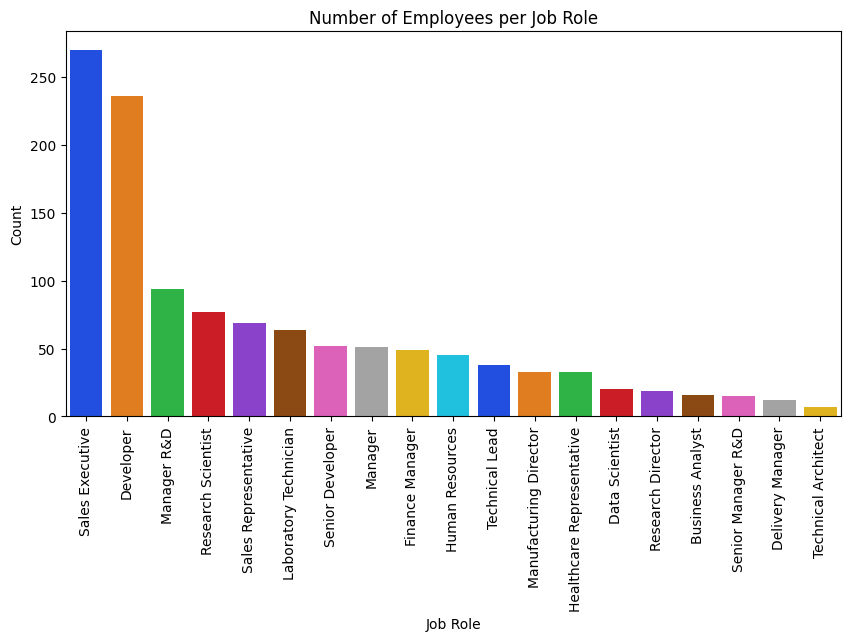

In [250]:
#EmpJobRole
plt.figure(figsize=(10,5))
job_order = data['EmpJobRole'].value_counts().index
sns.countplot(x='EmpJobRole',data=data,order=job_order,palette='bright')
plt.title('Number of Employees per Job Role')
plt.ylabel('Count')
plt.xlabel('Job Role')
plt.xticks(rotation=90)
plt.show()



##Majority of employees are sales Executive, followerd by Developers and least being technical archtets this suggest that the company sales are more

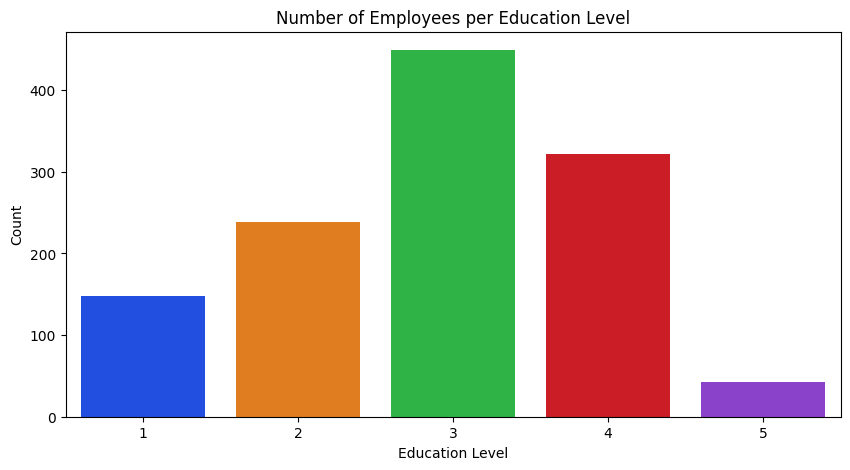

In [251]:
#EmpEducationLevel
plt.figure(figsize=(10,5))
sns.countplot(x='EmpEducationLevel',data=data,palette='bright')
plt.title('Number of Employees per Education Level')
plt.ylabel('Count')
plt.xlabel('Education Level')
plt.show()

##The majority of employees hold a Bachelor’s degree, followed by those with a Master’s degree, while the Doctorate level is the least represented.

#**What does This means**
##The organization’s talent pool is heavily concentrated at the undergraduate level, which is typical in many industries where a Bachelor’s degree is the standard entry requiremen

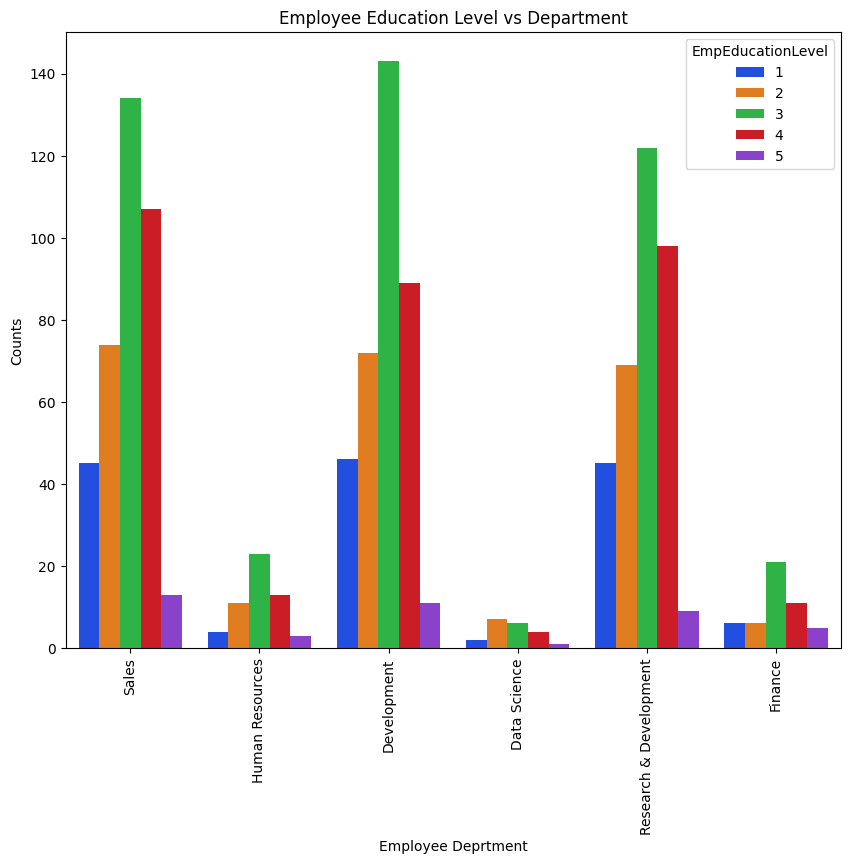

In [252]:
#Employee education level vs department
plt.figure(figsize=(10,8))
sns.countplot(x='EmpDepartment',hue='EmpEducationLevel', data=data,  palette='bright')
plt.title('Employee Education Level vs Department')
plt.ylabel('Counts')
plt.xlabel('Employee Deprtment')
plt.xticks(rotation=90)
plt.show()

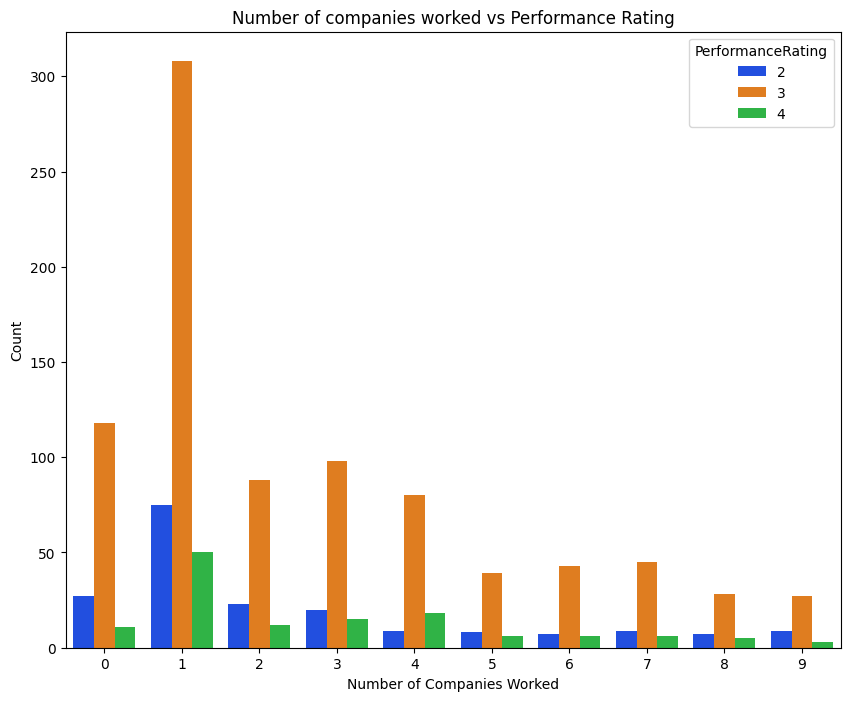

In [253]:
#NumCompaniesWorked vs performance Ratings
plt.figure(figsize=(10,8))
sns.countplot(x='NumCompaniesWorked', hue='PerformanceRating', data=data, palette='bright')
plt.title('Number of companies worked vs Performance Rating')
plt.ylabel('Count')
plt.xlabel('Number of Companies Worked')
plt.show()

##**Dominant Performance Rating:** Across almost all experience levels, a Performance Rating of 3 (Excellent) is the most common.

##**Peak Performance Volume**: The highest concentration of top performers occurs among those with one prior company, peaking at over 300 employees with a rating of 3.

##**High Achievers (Rating 4 - Outstanding):** These employees are less common but present at every experience level, with slight concentrations among those who have worked at 1 or 4 previous companies.

#**Key Note:** Having worked at a high number of companies (5–9) does not correlate with higher performance ratings; in fact, the total count of employees in these brackets drops significantly.

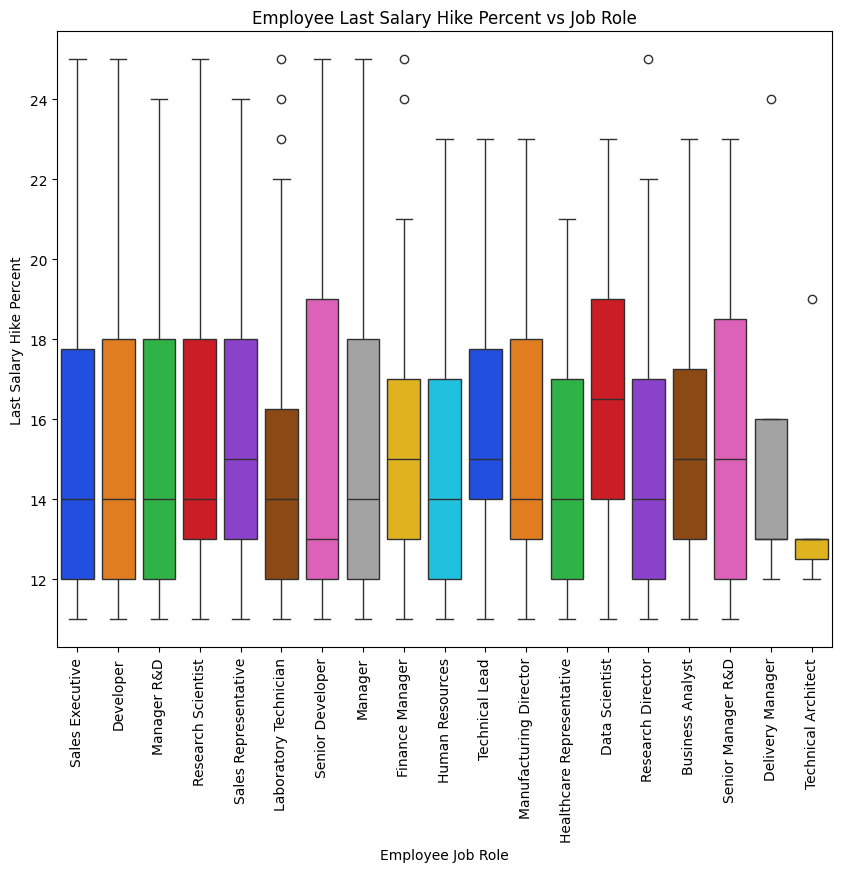

In [254]:
#EmpLastSalaryHikePercent vs Job role
plt.figure(figsize=(10,8))
job_order = data['EmpJobRole'].value_counts().index
sns.boxplot(x='EmpJobRole', y='EmpLastSalaryHikePercent', data=data,order=job_order, palette='bright')
plt.title('Employee Last Salary Hike Percent vs Job Role')
plt.ylabel('Last Salary Hike Percent')
plt.xlabel('Employee Job Role')
plt.xticks(rotation=90)
plt.show()


###Top Growth Roles: Data Scientists see the highest median salary hikes at approximately 16.5%

###Standardized Compensation: Most core roles including  Sales Executives, and Managers receive a median hike clustered around 14%.

###Conservative Hikes: Technical Architects receive the most compressed and lowest hikes, generally between 12% and 13%.

##Exceptional Adjustments: Some roles like Laboratory Technician and Research Director have "outlier" hikes reaching as high as 25%.

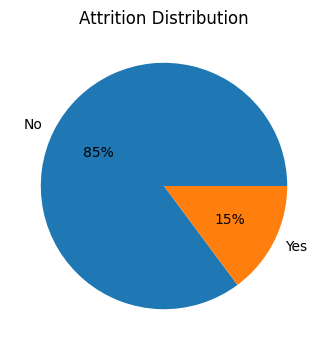

In [255]:
#Atritions Distriputions
plt.figure(figsize=(4,4))
counts = data['Attrition'].value_counts()

plt.pie(counts,labels=counts.index, autopct='%1.0f%%')
plt.title('Attrition Distribution')
plt.show()

##**No (Retained)-85%,** Represents the stable core of the company.
## **Yes(Attrited)-15%**, Represents employees who have left the company.

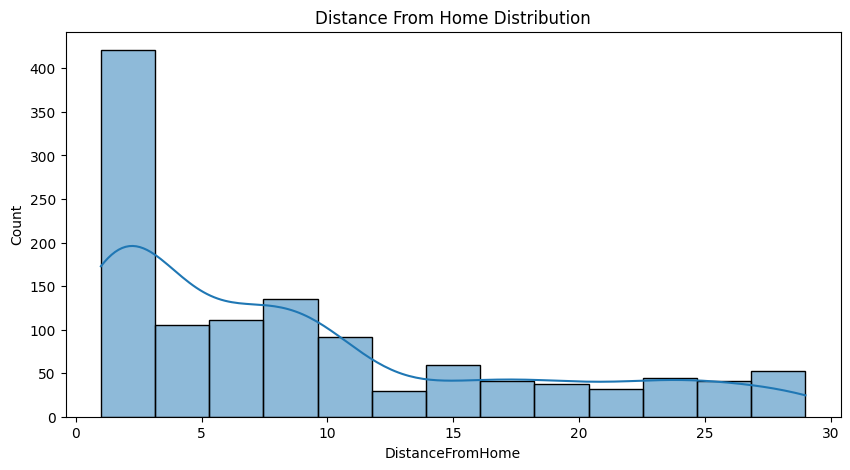

In [256]:
#Distance from home Distributions
plt.figure(figsize=(10,5))
sns.histplot(data['DistanceFromHome'], kde=True)
plt.title('Distance From Home Distribution')
plt.show()

###This is right skewed distributions or positive skewed ditributions
###There is a massive spike at the very beginning of the scale. Over 400 employees live within a very short distance from the office.

###The Mid-Range Drop-off: Once you move past the 10 mark, the numbers drop significantly. Most of your staff seems to prioritize a short commute.

###The Commuter Tail, There is a thin but steady "tail" extending all the way to 30. While these employees are fewer in number, they represent the group most at risk for "commute burnout," which often correlates with the 15% attrition rate we saw earlier.

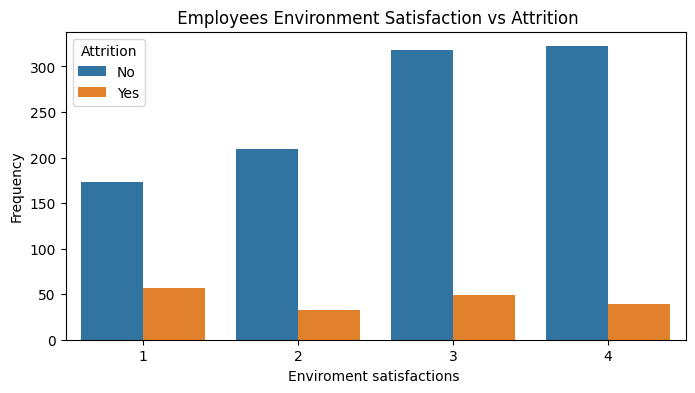

In [257]:
#Environment Satisfaction vs Attrition
plt.figure(figsize=(8,4))
sns.countplot(x='EmpEnvironmentSatisfaction', hue='Attrition', data=data)
plt.title(' Employees Environment Satisfaction vs Attrition')
plt.ylabel('Frequency')
plt.xlabel('Enviroment satisfactions ')
plt.show()

###The "At-Risk" Group ( 1): Employees with the lowest environment satisfaction show the highest relative attrition, with nearly 60 employees leaving in this category.

###Retention Sweet Spot (3 & 4): Employees who report high satisfaction (3 and 4) are much more likely to stay, with over 300 employees in each of these categories remaining at the company.

## Even though there are far more employees in the high-satisfaction groups, the total number of departures (Yes) is visibly lower in 3 and 4 than in the dissatisfied 1.

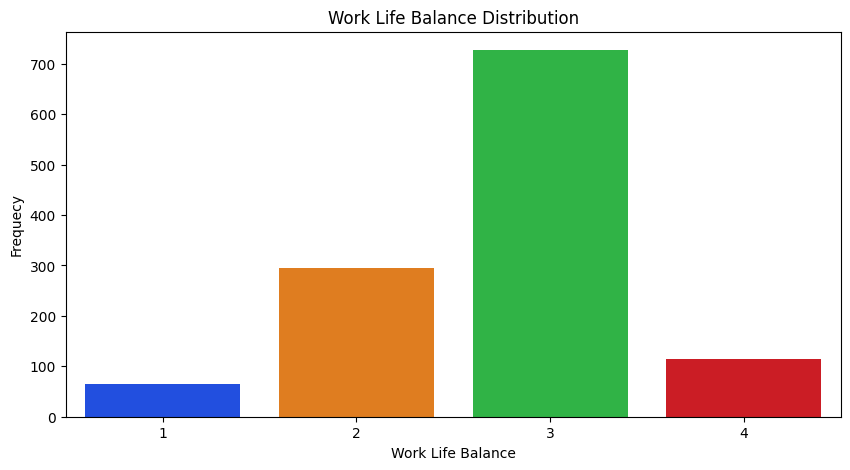

In [258]:
#Work Life Balance Distribution
plt.figure(figsize=(10,5))
sns.countplot(x='EmpWorkLifeBalance', data=data, palette='bright')
plt.title('Work Life Balance Distribution')
plt.xlabel('Work Life Balance')
plt.ylabel('Frequecy')
plt.show()

##The "Better" Majority: 3 ('Better') is the most frequent rating, with over 700 employees.

##Moderate Balance: Roughly 300 employees feel their work-life balance is 2 ('Good').

###The Extremes: A small segment of the population experiences either a 1 ('Bad') balance (approx. 70 employees) or a 4 ('Best') balance (approx. 110 employees).

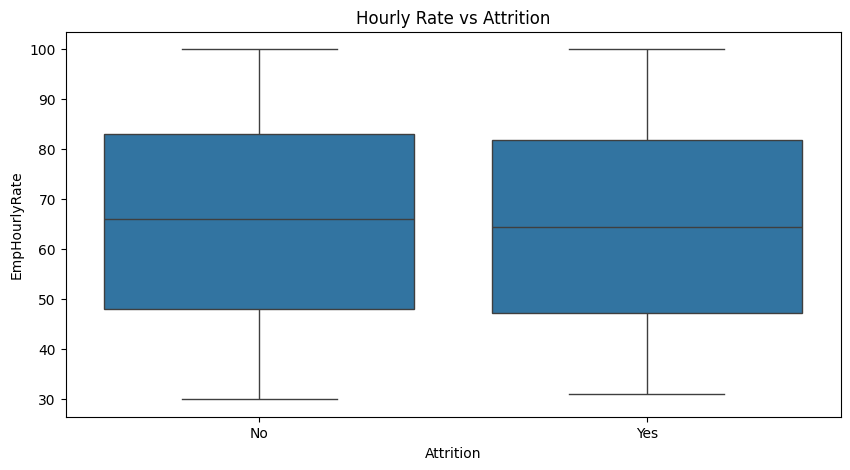

In [259]:
#Monthly Income vs Attrition
plt.figure(figsize=(10,5))
sns.boxplot(x='Attrition', y='EmpHourlyRate', data=data)
plt.title('Hourly Rate vs Attrition')
plt.show()

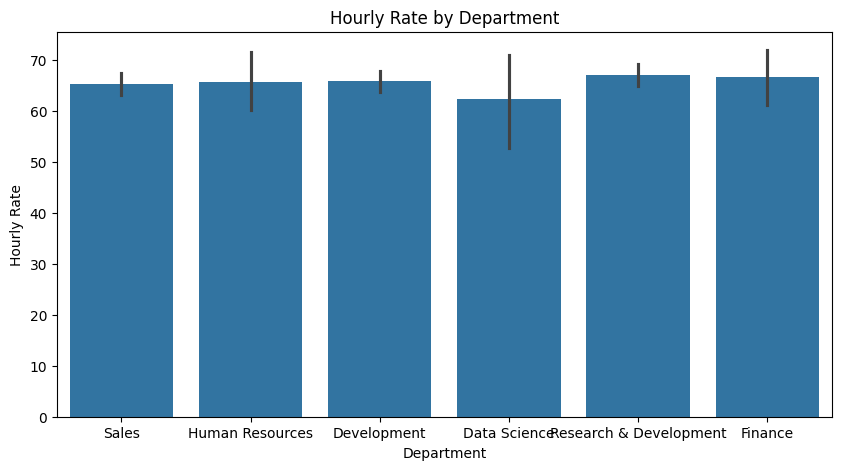

In [260]:
#hourl rate by departmets
plt.figure(figsize=(10,5))
sns.barplot(x='EmpDepartment', y='EmpHourlyRate', data=data)
plt.title('Hourly Rate by Department')
plt.xlabel('Department')
plt.ylabel('Hourly Rate')
plt.show()

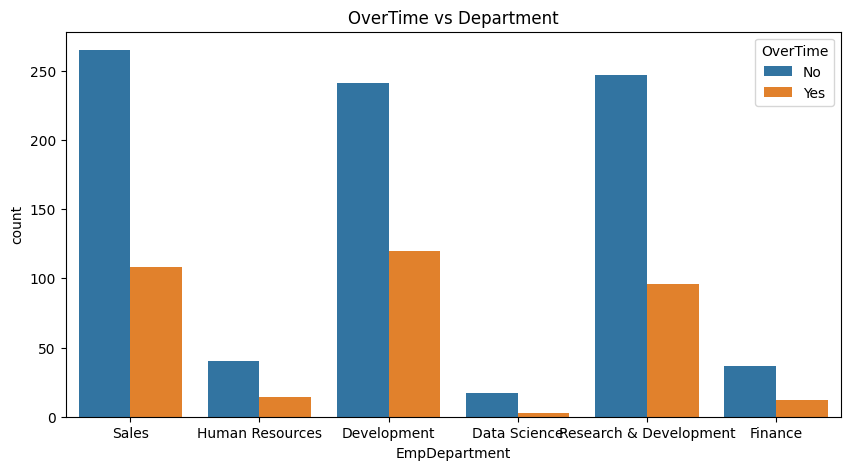

In [261]:
#OverTime vs department
plt.figure(figsize=(10,5))
sns.countplot(hue='OverTime', x='EmpDepartment', data=data)
plt.title('OverTime vs Department')
plt.show()

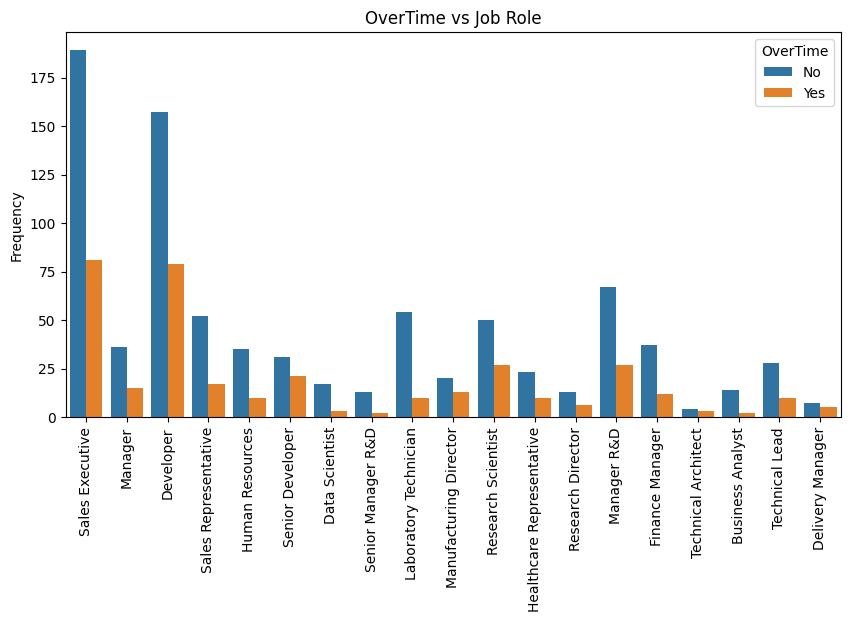

In [262]:
#Over time vs Job role
plt.figure(figsize=(10,5))
sns.countplot(hue='OverTime', x='EmpJobRole', data=data)
plt.title('OverTime vs Job Role')
plt.ylabel('Frequency')
plt.xlabel('')
plt.xticks(rotation=90)
plt.show()

###Sales Executives and Developers have the highest frequency of employees both working and not working overtime.

###For Sales Executives, nearly 80 employees regularly work overtime, while over 180 do not.

###Roles like Data Scientists and Senior Managers R&D show very low overtime requirements, with fewer than 5–10 employees in those roles reporting "Yes" for overtime.

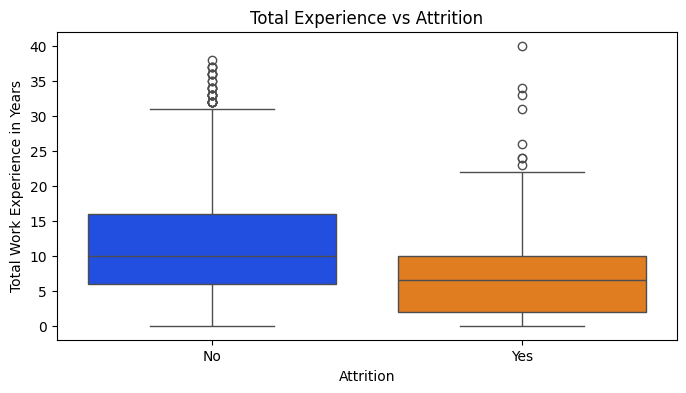

In [263]:
# experience vs attrition
plt.figure(figsize=(8,4))
sns.boxplot(x='Attrition', y='TotalWorkExperienceInYears', data=data,palette='bright')
plt.title('Total Experience vs Attrition')
plt.xlabel('Attrition')
plt.ylabel('Total Work Experience in Years')
plt.show()

Employees who stay with the company ("No" Attrition) have a notably higher median work experience—roughly 10 years—compared to those who leave ("Yes" Attrition), whose median is approximately 7 years.

The Early Career Risk Zone,  The "Yes" group's interquartile range  is concentrated between 2 and 10 years of experience. This suggests that employees in their first decade of total work experience are more likely to depart.

The risk of losing an employee is significantly higher during their first 10 years of total career experience

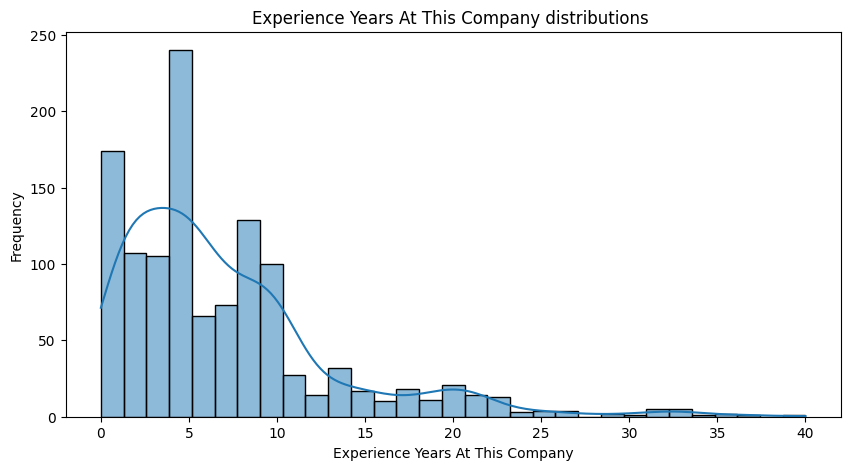

In [264]:
#Experience Years At This Company distributions
plt.figure(figsize=(10,5))
sns.histplot(data['ExperienceYearsAtThisCompany'], kde=True)
plt.title('Experience Years At This Company distributions ')
plt.xlabel('Experience Years At This Company')
plt.ylabel('Frequency')
plt.show()

Peak Tenure: The highest frequency of employees occurs at approximately 5 years of experience at the company, with over 240 individuals in this category.

Early Career Concentration: The workforce is heavily weighted toward newer staff, with the largest volume of employees falling between 0 and 10 years of tenure.

Initial Entry: There is a significant initial group of approximately 175 employees with near 0 years of experience, suggesting recent hiring activity.

The "Long Tail": Frequency drops significantly after the 10-year mark. However, the distribution extends as far as 40 years, indicating a small but present group of long-term veterans.

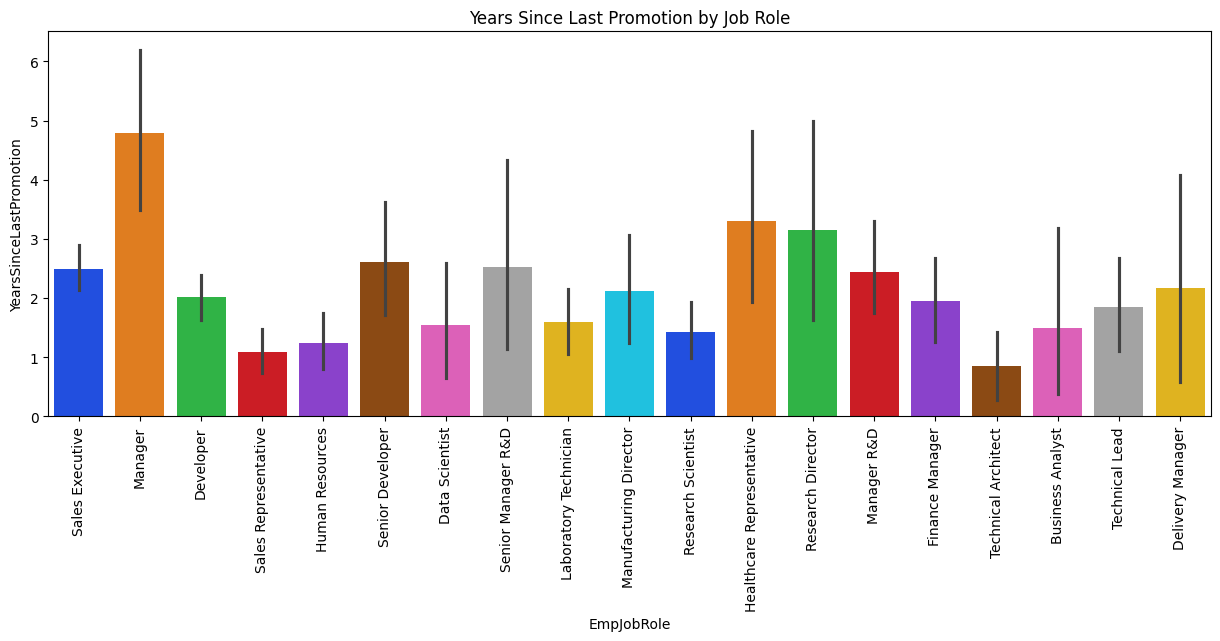

In [265]:
#YearsSinceLastPromotion by Job role
plt.figure(figsize=(15,5))
sns.barplot(x='EmpJobRole', y='YearsSinceLastPromotion',data=data, palette='bright')
plt.title('Years Since Last Promotion by Job Role')
plt.xticks(rotation=90)
plt.show()

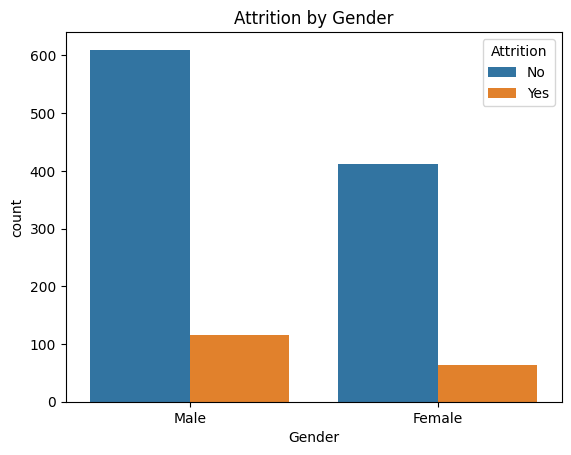

In [266]:
#Attrition by Gender
sns.countplot(x='Gender', hue='Attrition', data=data)
plt.title('Attrition by Gender')
plt.show()

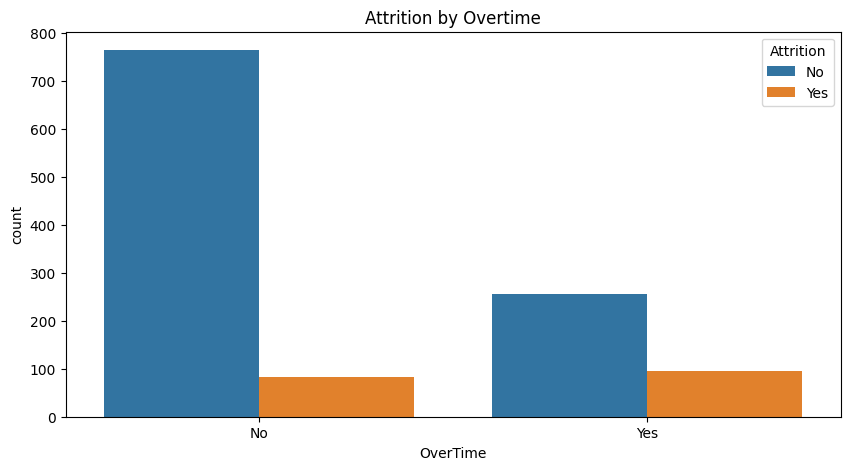

In [267]:
#attrition over time
plt.figure(figsize=(10,5))
sns.countplot(x='OverTime', hue='Attrition', data=data)
plt.title('Attrition by Overtime')
plt.show()

Employees who do not work overtime have a very high "No Attrition" count. Only a small portion of them leave.

Among employees who work overtime, the number of employees leaving is noticeably higher compared to those who don’t.

There is a strong positive relationship between overtime and attrition. Employees who work overtime are more likely to leave the organization compared to those who do not work overtime

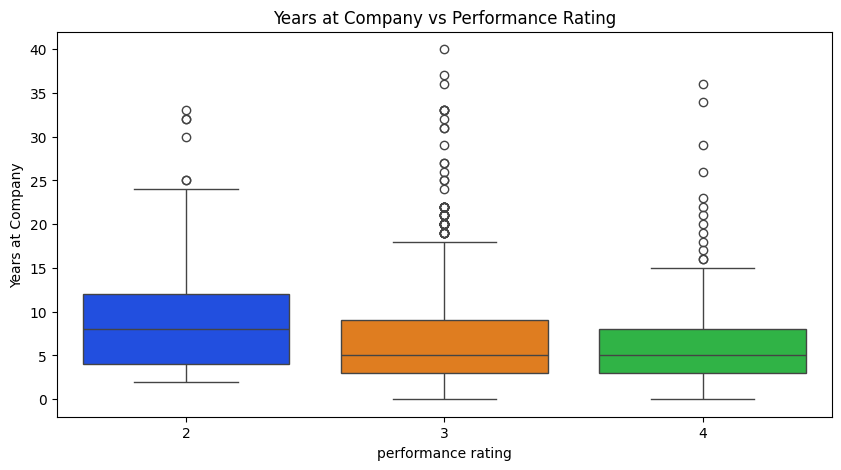

In [268]:
#Years at Company vs perfomance rating 
plt.figure(figsize=(10,5))
sns.boxplot(x='PerformanceRating', y='ExperienceYearsAtThisCompany', data=data, palette='bright')
plt.title('Years at Company vs Performance Rating')
plt.xlabel('performance rating')
plt.ylabel('Years at Company')
plt.show()

There is a slight inverse relationship between tenure and performance. Employees with a rating of 2 (the lowest shown) actually tend to have a higher median tenure (around 8 years) compared to those with a rating of 3 or 4 (median tenure around 5 years).

Most high performers (Rating 4) are relatively new employees to the company. The bulk of this group falls between 3 and 8 years of tenure.

The Outliers: All three categories show significant outliers employees who have stayed 20 to 40 years. Interestingly, the Rating 3 category has the highest number of long-tenured outliers, including someone who has been there for 40 years.

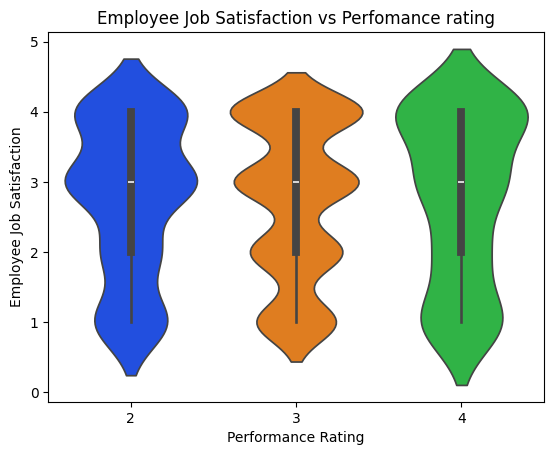

In [269]:
#Employee Job Satisfaction vs Perfomance rating
sns.violinplot(x='PerformanceRating', y='EmpJobSatisfaction', data=data, palette='bright')
plt.title('Employee Job Satisfaction vs Perfomance rating')
plt.xlabel('Performance Rating')
plt.ylabel('Employee Job Satisfaction')
plt.show()

For Ratings 2, 3, and 4, the central tendency appears close to 3. This suggests moderate satisfaction is common regardless of performance rating.

Employees with Performance Rating 4 show: More density at satisfaction 3 and 4.

Fewer extremely low satisfaction values compared to rating 2.

Rating 2 employees show more variation toward lower satisfaction levels.

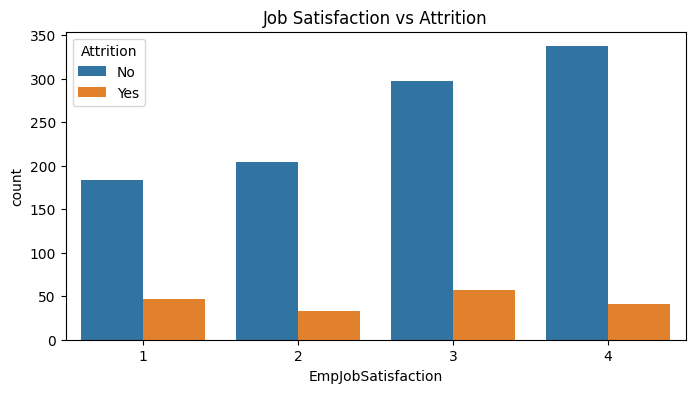

In [270]:
#job satisfactions vs attritions
plt.figure(figsize=(8,4))
sns.countplot(x='EmpJobSatisfaction', hue='Attrition', data=data)
plt.title('Job Satisfaction vs Attrition')
plt.show()

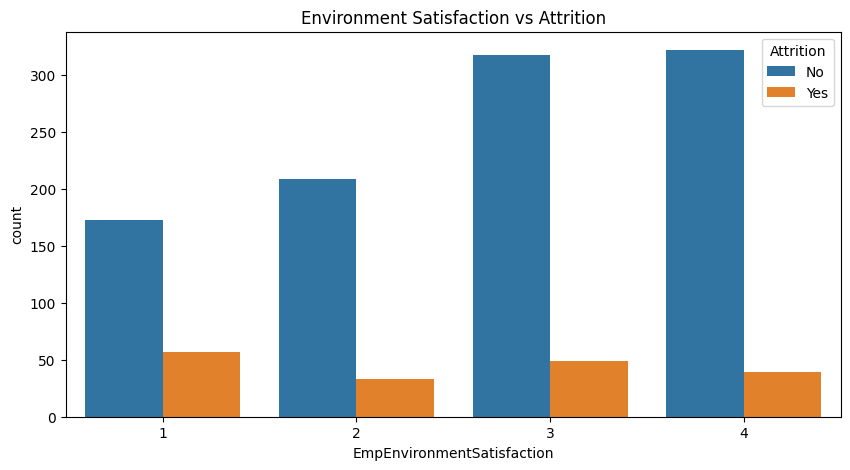

In [271]:
#Environment Satisfaction vs Attrition
plt.figure(figsize=(10,5))
sns.countplot(x='EmpEnvironmentSatisfaction', hue='Attrition', data=data)
plt.title('Environment Satisfaction vs Attrition')
plt.show()

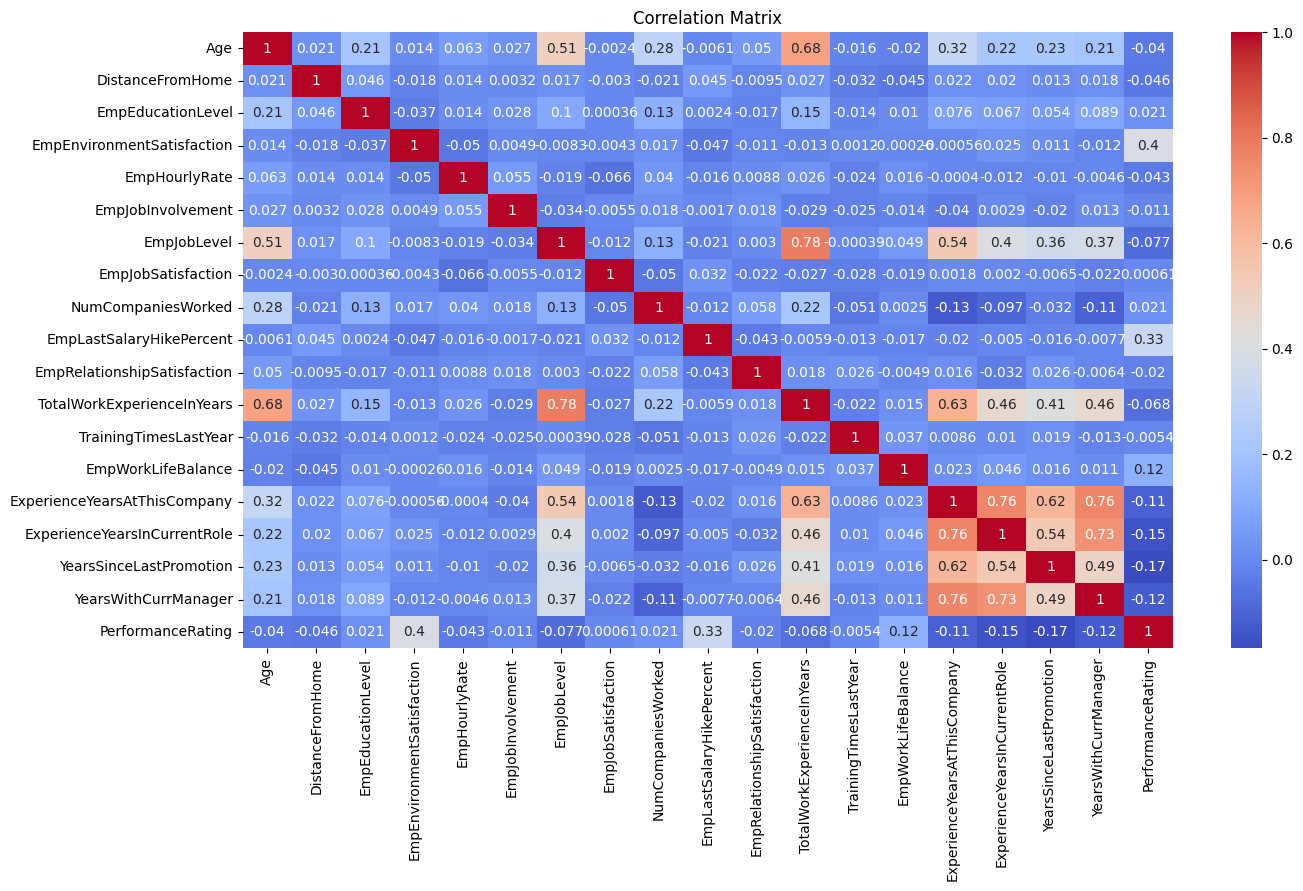

In [272]:
#correlation matrix
plt.figure(figsize=(15,8))
numeric_data=data.select_dtypes(include=['int64','float64'])
sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


DATA PREPARATIONS 

OUTLIERS REMOVAL 

In [273]:
#copy of dataset
data_copy=data.copy()


In [274]:
data_copy.drop(columns=['EmpNumber'], inplace=True,axis=1)

Remove Id which is not necessary 

In [275]:
#Outlier detection and Removal IQR
def remove_outliers_iqr(data_copy,column):
  Q1=data_copy[column].quantile(0.25)
  Q3=data_copy[column].quantile(0.75)
  IQR=Q3-Q1
  lower_bound=Q1-1.5*IQR
  upper_bound=Q3+1.5*IQR
  outliers=data_copy[(data_copy[column]<lower_bound) | (data_copy[column]>upper_bound)]#Outlier detection
  cleaned=data_copy[(data_copy[column]>=lower_bound) & (data_copy[column]<=upper_bound)] #Outlier Removal
  print(f'Outliers detected in {column}: {len(outliers)}')
  print(f"Before: {data_copy.shape}, After removal: {cleaned.shape}")
  return cleaned

In [276]:
#remove outliers from the dataset terget variable
cleaned_data_iqr=remove_outliers_iqr(data_copy,'YearsSinceLastPromotion')

Outliers detected in YearsSinceLastPromotion: 88
Before: (1200, 27), After removal: (1112, 27)


ENCODING

In [ ]:
# Create a copy of your data
data_copy = cleaned_data_iqr.copy()  # Replace with your actual DataFrame name

# Identify categorical columns (excluding target)
categorical_cols = data_copy.select_dtypes(include=['object']).columns.tolist()
if 'PerformanceRating' in categorical_cols:
    categorical_cols.remove('PerformanceRating')

# Apply Label Encoding
le = LabelEncoder()
for col in categorical_cols:
    data_copy[col] = le.fit_transform(data_copy[col])

data_copy.head()

,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,...,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,32,1,2,2,5,13,2,10,3,4,...,4,10,2,2,10,7,0,8,0,3
1,47,1,2,2,5,13,2,14,4,4,...,4,20,2,3,7,7,1,7,0,3
2,40,1,1,1,5,13,1,5,4,4,...,3,20,2,3,18,13,1,12,0,4
4,60,1,2,2,5,13,2,16,4,1,...,4,10,1,3,2,2,2,2,0,3
5,27,1,1,0,1,3,1,10,2,4,...,3,9,4,2,9,7,1,7,0,4


In [279]:
#UNIQUE VALUES IN THE TARGET VARIABLE
data_copy['PerformanceRating'].unique()

array([3, 4, 2])

MODELLLING 

Logistics regression

In [280]:
#Identifying the target variable and features
X = data_copy.drop('PerformanceRating', axis=1)
y = data_copy['PerformanceRating']

In [282]:
#split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

In [283]:
#scalling the features
scaler=StandardScaler()
X_train= scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


In [284]:
#initializing logistic model 
logistic_model=LogisticRegression()
logistic_model.fit(X_train, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [285]:
#model training
y_pred_logistic=logistic_model.predict(X_train)

In [286]:
#logistic regression predictions
y_pred_logistic=logistic_model.predict(X_test)

In [287]:
#Evaluation of the model
report_logistic=classification_report(y_test, y_pred_logistic)
print(report_logistic)

              precision    recall  f1-score   support

           2       0.67      0.59      0.62        34
           3       0.88      0.92      0.90       164
           4       0.77      0.68      0.72        25

    accuracy                           0.84       223
   macro avg       0.77      0.73      0.75       223
weighted avg       0.84      0.84      0.84       223



The accuracy of the model is 85% accurate 
there is class inbalance the predictions support as show with low precesions in the ratings of 2


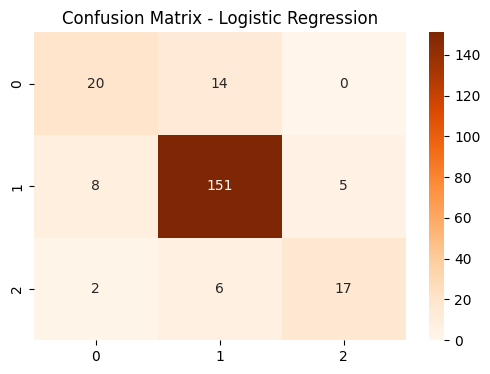

In [288]:
#confusion matrix logistics 
cm_logistic=confusion_matrix(y_test, y_pred_logistic)
plt.figure(figsize=(6,4))
sns.heatmap(cm_logistic, annot=True, fmt='d', cmap='Oranges')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()


Hyper parameter Tuning 

In [289]:
log_model_tuned=LogisticRegression()
param_grid={'penalty':['l1','l2'],
            'C':[0.001,0.01,0.1,1,10,100,1000],
            'multi_class':['multinomial'],
            'solver':['liblinear','saga']
            }

In [290]:
grid_log_model=GridSearchCV(log_model_tuned,param_grid,cv=10)
grid_log_model.fit(X_train,y_train)
print(grid_log_model.best_params_)

{'C': 1, 'multi_class': 'multinomial', 'penalty': 'l1', 'solver': 'saga'}


In [291]:
final_log_model=LogisticRegression(**grid_log_model.best_params_)
final_log_model.fit(X_train,y_train)

,penalty,'l1'
,dual,False
,tol,0.0001
,C,1
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'saga'
,max_iter,100
,multi_class,'multinomial'


In [292]:
#prediction
y_pred_log_final=final_log_model.predict(X_test)

In [293]:
#report print
report_log_final=classification_report(y_test,y_pred_log_final)
print(report_log_final)

              precision    recall  f1-score   support

           2       0.68      0.56      0.61        34
           3       0.88      0.93      0.90       164
           4       0.77      0.68      0.72        25

    accuracy                           0.84       223
   macro avg       0.78      0.72      0.75       223
weighted avg       0.84      0.84      0.84       223



The accuracy of the model predictions is 85% 

In [294]:
#confusion matrix
confusion_matrix_log_final=confusion_matrix(y_test,y_pred_log_final)
print(confusion_matrix_log_final)

[[ 19  15   0]
 [  7 152   5]
 [  2   6  17]]


Class Performance

Class 0: 14 correct, 12 misclassified as Class 1 → weak performance.

Class 1: 170 correct → best predicted class.

Class 2: 19 correct, some confused with Class 1 → moderate performance.

Random Forest classifiations 

In [295]:
#split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [296]:
#scalling the features
scaler=StandardScaler()
X_train= scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


In [297]:
#random forest classifier model
rf_model=RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [298]:
#model training
y_pred_rf=rf_model.predict(X_train)

In [299]:
#model testing
y_pred_rf=rf_model.predict(X_test)

In [300]:
#Evaluation of the model
report_rf=classification_report(y_test, y_pred_rf)
print(report_rf)

              precision    recall  f1-score   support

           2       0.86      0.88      0.87        34
           3       0.93      0.94      0.94       161
           4       0.84      0.75      0.79        28

    accuracy                           0.91       223
   macro avg       0.88      0.86      0.87       223
weighted avg       0.91      0.91      0.91       223



The model accuracy is 95% hence this is the best model for predictions 


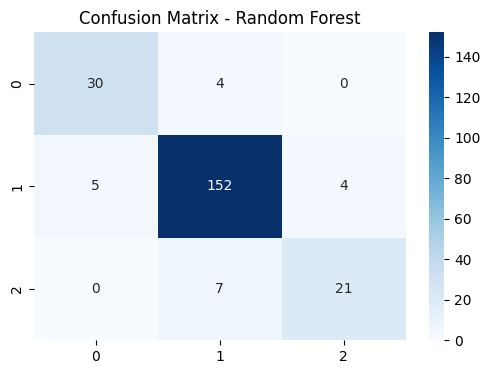

In [301]:
#confusion matrix for random forest 
cm_rf=confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6,4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.show()

SUPPORT VECTOR MACHINE LEARNING 

In [302]:
#split the model
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [303]:
#scalling the features
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [304]:
#intialized SVM
svm=SVC(kernel='linear')
svm.fit(X_train,y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [305]:
#Make predictions 
y_pred_svm=svm.predict(X_test)

In [306]:
report=classification_report(y_test,y_pred_svm)
print(report)

              precision    recall  f1-score   support

           2       0.51      0.56      0.54        34
           3       0.87      0.88      0.87       161
           4       0.83      0.68      0.75        28

    accuracy                           0.80       223
   macro avg       0.73      0.70      0.72       223
weighted avg       0.81      0.80      0.80       223



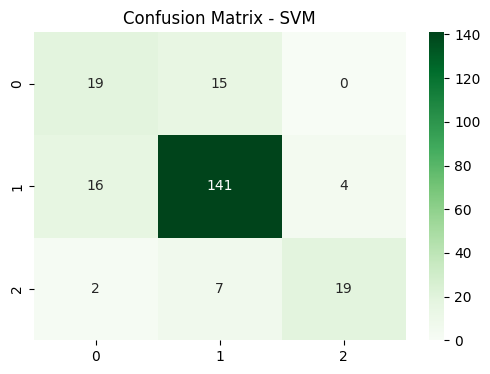

In [307]:
#SVM Confusion matrix
cm_svm=confusion_matrix(y_test,y_pred_svm)
plt.figure(figsize=(6,4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens')
plt.title('Confusion Matrix - SVM')
plt.show()

Support Vector Machine learning 

In [308]:
#training model
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)

In [309]:
#initialized scaller
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [310]:
model=SVC(kernel='linear',random_state=42)
model.fit(X_train,y_train)



,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [311]:
y_pred=model.predict(X_test)

In [312]:
report=classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           2       0.62      0.48      0.54        50
           3       0.85      0.91      0.88       246
           4       0.77      0.61      0.68        38

    accuracy                           0.81       334
   macro avg       0.74      0.67      0.70       334
weighted avg       0.80      0.81      0.81       334



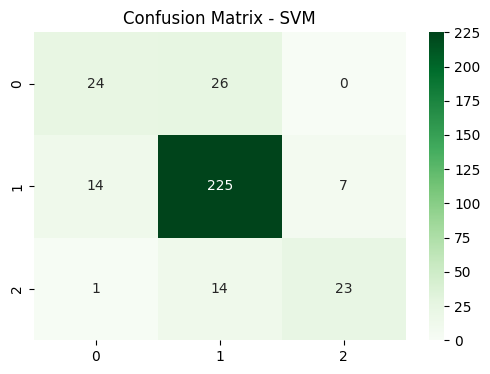

In [313]:
#Confusion matrix for SVM
cm_svm=confusion_matrix(y_test,y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens')
plt.title('Confusion Matrix - SVM')
plt.show()

PRINCIPALE COMPONENET ANALYSIS 

In [314]:
pca=PCA(n_components=2)
X_train_pca=pca.fit_transform(X_train)
X_test_pca=pca.transform(X_test)

In [315]:
#svc model
svm_pca_linear=SVC(kernel='linear')
svm_pca_linear.fit(X_train_pca,y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [316]:
#predict the model
y_pred_pca_linear=svm_pca_linear.predict(X_test_pca)

In [317]:
report_pca_linear=classification_report(y_test,y_pred_pca_linear)
print(report_pca_linear)

              precision    recall  f1-score   support

           2       0.00      0.00      0.00        50
           3       0.74      1.00      0.85       246
           4       0.00      0.00      0.00        38

    accuracy                           0.74       334
   macro avg       0.25      0.33      0.28       334
weighted avg       0.54      0.74      0.62       334



In [318]:
#RBF --This comes from the support vectors --this tries to measure simmiliarities based on distance between the points
svm_pca_rbf=SVC(kernel='rbf')
svm_pca_rbf.fit(X_train_pca,y_train)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [319]:
#making predictions
y_pred_pca_rbf=svm_pca_rbf.predict(X_test_pca)

In [320]:
#Print report
report_pca_rbf=classification_report(y_test,y_pred_pca_rbf)
print(report_pca_rbf)

              precision    recall  f1-score   support

           2       0.00      0.00      0.00        50
           3       0.74      1.00      0.85       246
           4       0.00      0.00      0.00        38

    accuracy                           0.74       334
   macro avg       0.25      0.33      0.28       334
weighted avg       0.54      0.74      0.62       334



In [321]:
#polynomial kernel--its slightly similary with RBF--
#--- compute the similarity using polynomial combination of input features
svm_pca_poly=SVC(kernel='poly')
svm_pca_poly.fit(X_train_pca,y_train)

,C,1.0
,kernel,'poly'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [322]:
#predictions
y_pred_pca_poly=svm_pca_poly.predict(X_test_pca)

In [323]:
#print the classifications \
report_pca_poly=classification_report(y_test,y_pred_pca_poly)
print(report_pca_poly)

              precision    recall  f1-score   support

           2       0.00      0.00      0.00        50
           3       0.74      1.00      0.85       246
           4       0.00      0.00      0.00        38

    accuracy                           0.74       334
   macro avg       0.25      0.33      0.28       334
weighted avg       0.54      0.74      0.62       334



In [324]:
#Decision Bounderies--predicting decision bounderies

def decision_boundary(model,X,y):
  X_min,X_max=X[:,0].min()-1,X[:,0].max()+1
  Y_min,Y_max=X[:,1].min()-1,X[:,1].max()+1
  x_mesh,y_mesh=np.meshgrid(np.arange(X_min,X_max,0.01),np.arange(Y_min,Y_max,0.01))#create a grid of values covering the PCA feature space
  Z=model.predict(np.c_[x_mesh.ravel(),y_mesh.ravel()])#predict the class of each point
  Z=Z.reshape(x_mesh.shape)
  plt.contourf(x_mesh,y_mesh,Z,alpha=0.4,cmap='coolwarm')#plotting where the model classifies datapoint as class 1 or 0
  plt.scatter(X[:,0],X[:,1],cmap='coolwarm',c=y)
  plt.xlabel('Feature 1')
  plt.ylabel('Feature 2')

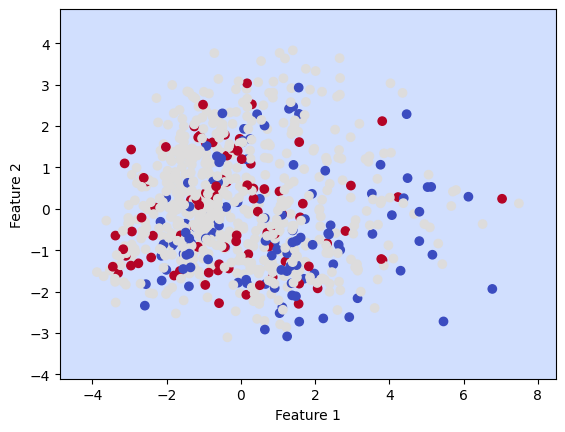

In [325]:
decision_boundary(svm_pca_linear,X_train_pca,y_train)

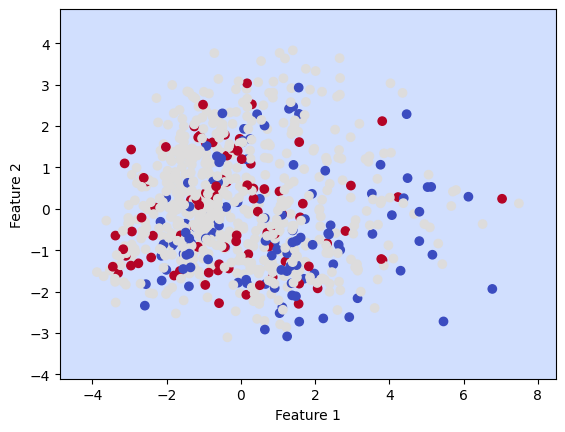

In [326]:
decision_boundary(svm_pca_rbf,X_train_pca,y_train)

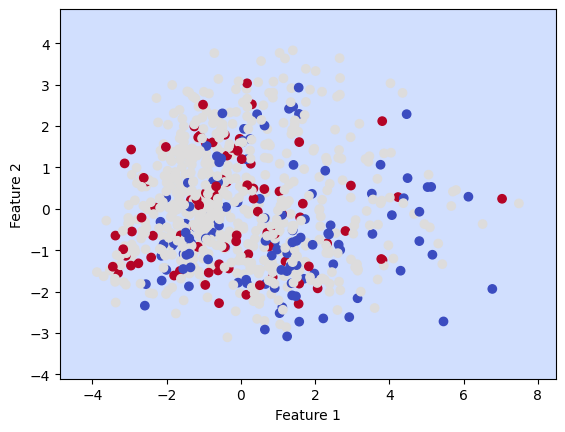

In [327]:
decision_boundary(svm_pca_poly,X_train_pca,y_train)

In [328]:
#pca as percentages
pca_var=PCA(n_components=0.90) #90% of the variance
X_train_pca_var=pca_var.fit_transform(X_train)
X_test_pca_var=pca_var.transform(X_test)

print('number of components:',pca_var.n_components_)



number of components: 19


#Gaussian Naive Bayes classifier

In [329]:
#split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [330]:
#scalling the features
scaller=StandardScaler()
X_train=scaller.fit_transform(X_train)
X_test=scaller.transform(X_test)

In [331]:
# Train a Gaussian Naive Bayes classifier
model = GaussianNB()
model.fit(X_train, y_train)

,priors,None
,var_smoothing,1e-09


In [332]:
y_pred = model.predict(X_test)


In [333]:
# Evaluate the model
report=classification_report(y_test, y_pred)
print(report)


print("Accuracy:", accuracy_score(y_test, y_pred))



              precision    recall  f1-score   support

           2       0.39      0.44      0.42        34
           3       0.83      0.83      0.83       161
           4       0.75      0.64      0.69        28

    accuracy                           0.75       223
   macro avg       0.66      0.64      0.65       223
weighted avg       0.76      0.75      0.75       223

Accuracy: 0.7488789237668162


support ilustrate the class that the support is given

#class 2=Good---there support for employee who were rated good
precision 0.55--out of all rated good 55% were correct predicted
recal 0.62--the model found 62% of all employees were rated good

#Class 3= those perform and rated excellent 
precision 0.90 =out of all rated excellent  90% were correct
recall 0.91==the model found that only 91% of actuall perform excellent 

accuracy--proportions of the data explained by the model --85%

#macro avrg=0.76 mean the average perfomance across all clasess classes

#weighted avrg=average perfomance weigthed by class size 0.85

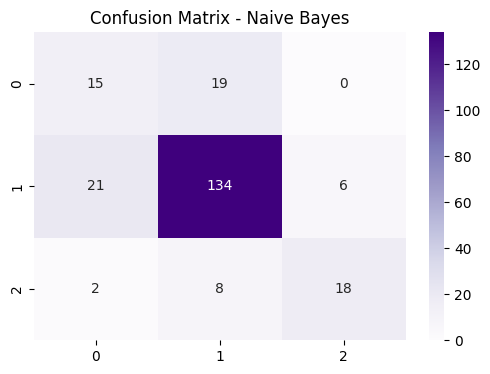

In [334]:
#confusion matrix for Naive Bayes
cm_nb=confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Purples')
plt.title('Confusion Matrix - Naive Bayes')
plt.show()


Class Performance

Class 0: 18 correct, many misclassified as Class 1 → weak performance.

Class 1: 167 correct → best predicted class.

Class 2: 19 correct, some confused with Class 1 → moderate performance.

XGBoosting Gradient

In [335]:
#split the dataset into training and testing sets
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)

In [336]:
#scalling the features
scaler=StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [337]:
#Gradient Boosting Classifier
model_gb=GradientBoostingClassifier()
model_gb.fit(X_train,y_train)


,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [338]:
#make predictions
y_pred_gb=model_gb.predict(X_test)

#classification report
report=classification_report(y_test,y_pred_gb)
print(report)

              precision    recall  f1-score   support

           2       0.93      0.84      0.88        50
           3       0.94      0.98      0.96       246
           4       0.91      0.76      0.83        38

    accuracy                           0.93       334
   macro avg       0.93      0.86      0.89       334
weighted avg       0.93      0.93      0.93       334



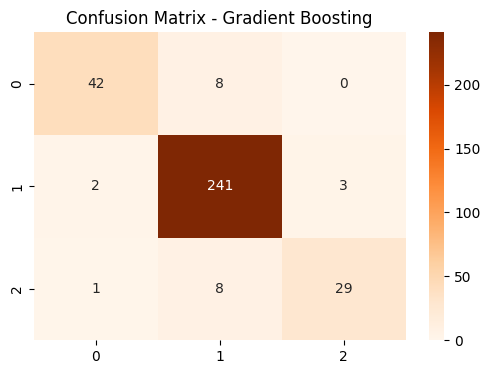

In [339]:
#confusion matrix for Gradient Boosting
cm_gb=confusion_matrix(y_test,y_pred_gb)
plt.figure(figsize=(6,4))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Oranges')
plt.title('Confusion Matrix - Gradient Boosting')
plt.show()

PERFOMING FEATURE IMPORTANCE FOR THE TOP THREE AS PER THE MOST RECOMENDED RANDOM FOREST MODEL 

In [340]:
# Extract feature importance from the trained Random Forest model
feature_importance = rf_model.feature_importances_

# Get feature names (assuming X is your feature dataframe)
feature_names = X.columns

# Create a dataframe for better visualization
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importance
})

# Sort by importance
importance_df = importance_df.sort_values('Importance', ascending=False)

In [341]:
print("=== FEATURE IMPORTANCE RANKINGS ===")
print(importance_df)
print("\n")


=== FEATURE IMPORTANCE RANKINGS ===
                         Feature  Importance
16      EmpLastSalaryHikePercent    0.217303
9     EmpEnvironmentSatisfaction    0.201152
23       YearsSinceLastPromotion    0.091876
5                     EmpJobRole    0.045217
22  ExperienceYearsInCurrentRole    0.041541
4                  EmpDepartment    0.034905
10                 EmpHourlyRate    0.034329
0                            Age    0.033402
21  ExperienceYearsAtThisCompany    0.032404
20            EmpWorkLifeBalance    0.031582
18    TotalWorkExperienceInYears    0.027492
7               DistanceFromHome    0.026080
24          YearsWithCurrManager    0.025198
14            NumCompaniesWorked    0.020404
8              EmpEducationLevel    0.017984
19         TrainingTimesLastYear    0.017061
17   EmpRelationshipSatisfaction    0.014851
2            EducationBackground    0.013709
12                   EmpJobLevel    0.013333
13            EmpJobSatisfaction    0.012050
11             EmpJ

In [342]:

# Display Top 3 Most Important Features
print("=== TOP 3 MOST IMPORTANT FEATURES ===")
top_3_features = importance_df.head(3)
for idx, row in top_3_features.iterrows():
    print(f"{row['Feature']}: {row['Importance']:.4f} ({row['Importance']*100:.2f}%)")

print("\n")


=== TOP 3 MOST IMPORTANT FEATURES ===
EmpLastSalaryHikePercent: 0.2173 (21.73%)
EmpEnvironmentSatisfaction: 0.2012 (20.12%)
YearsSinceLastPromotion: 0.0919 (9.19%)




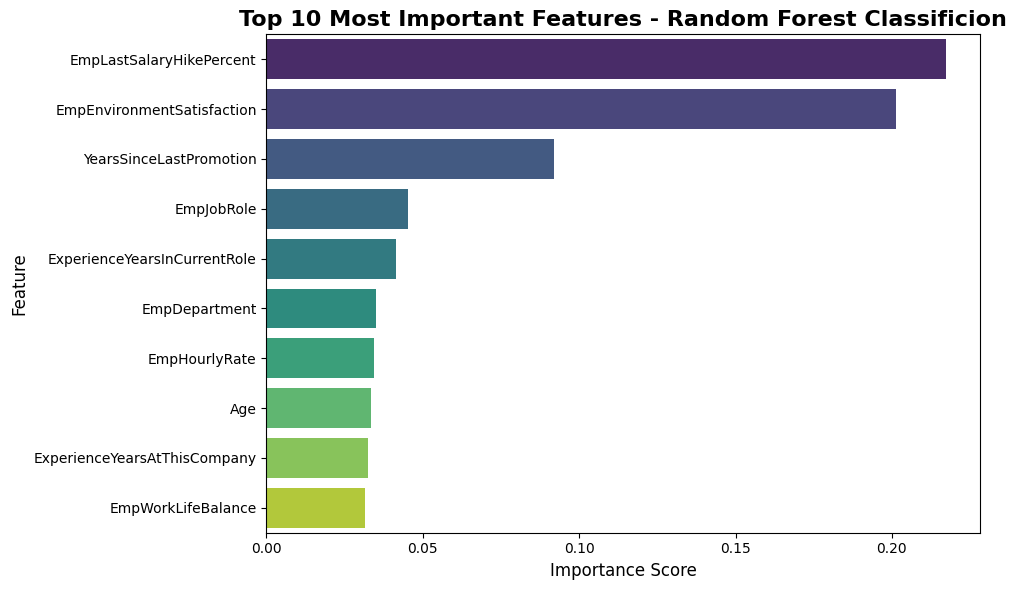

In [343]:
# ========================================
# VISUALIZATION 1: Bar Plot of Top 10 Features
# ========================================
plt.figure(figsize=(10, 6))
top_10 = importance_df.head(10)
sns.barplot(x='Importance', y='Feature', data=top_10, palette='viridis')
plt.title('Top 10 Most Important Features - Random Forest Classificion', fontsize=16, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

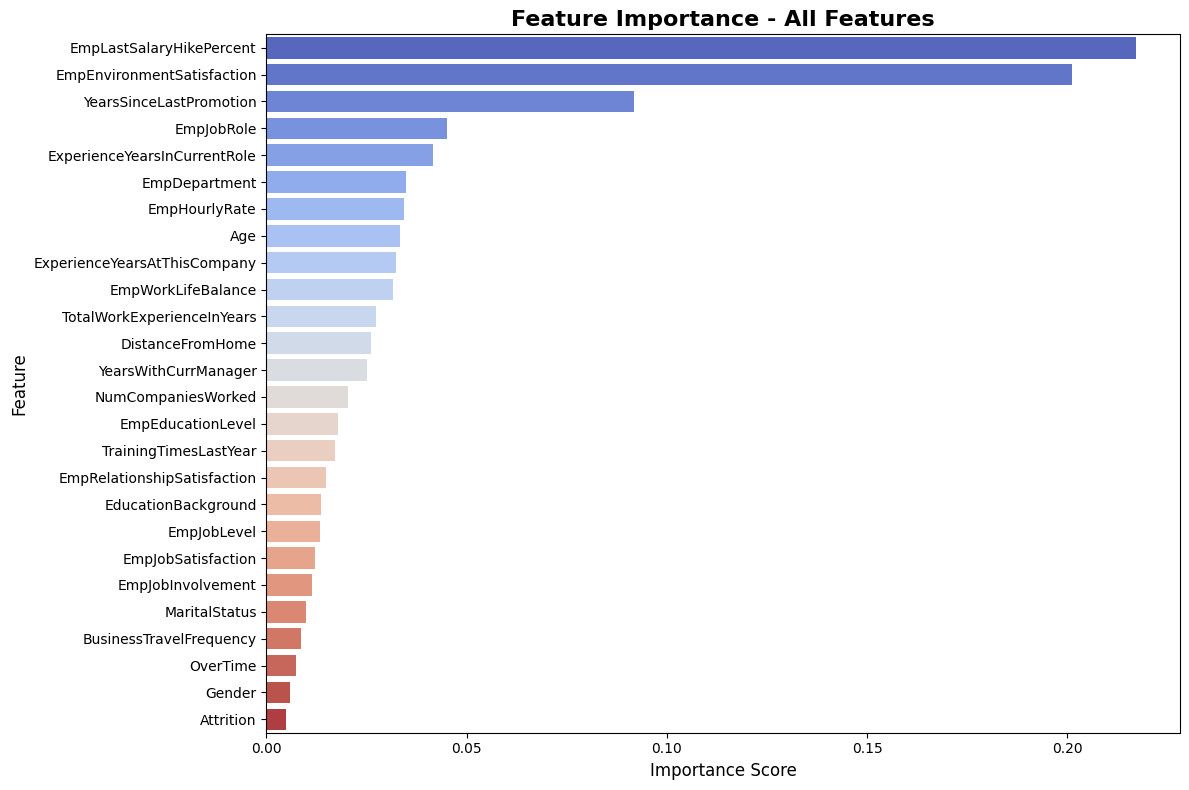

In [344]:
# ========================================
# VISUALIZATION 2: Horizontal Bar Chart for All Features
# ========================================
plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=importance_df, palette='coolwarm')
plt.title('Feature Importance - All Features', fontsize=16, fontweight='bold')
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

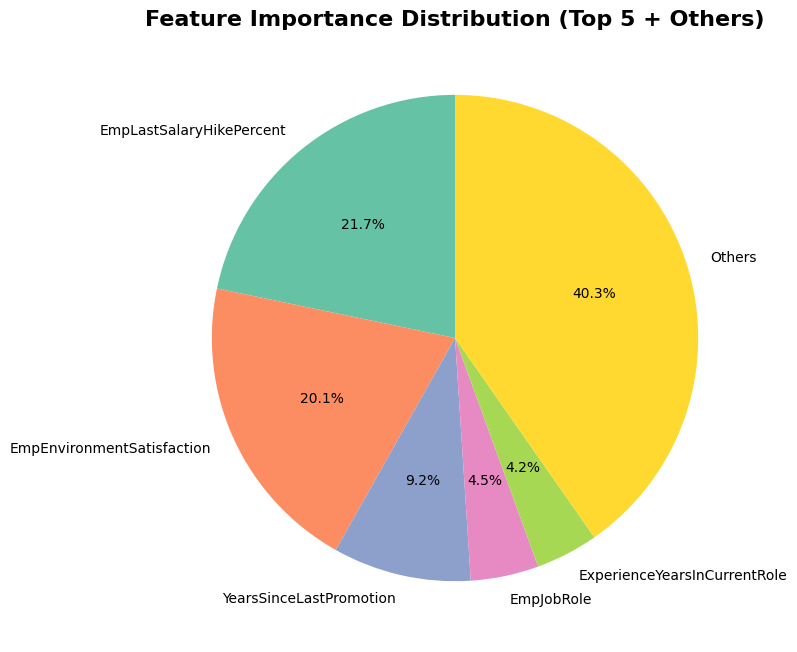

In [345]:
# ========================================
# VISUALIZATION 3: Pie Chart for Top 5 Features
# ========================================
plt.figure(figsize=(8, 8))
top_5 = importance_df.head(5)
other_importance = importance_df.iloc[5:]['Importance'].sum()

# Prepare data for pie chart
pie_data = top_5['Importance'].tolist() + [other_importance]
pie_labels = top_5['Feature'].tolist() + ['Others']

plt.pie(pie_data, labels=pie_labels, autopct='%1.1f%%', startangle=90, 
        colors=sns.color_palette('Set2'))
plt.title('Feature Importance Distribution (Top 5 + Others)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


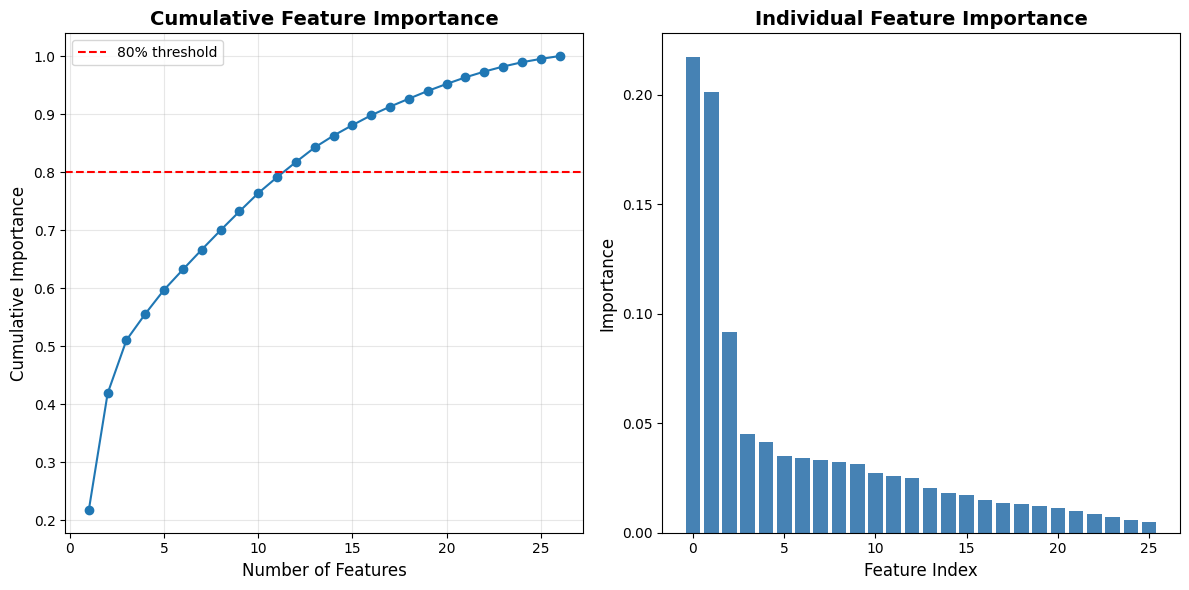

In [346]:

# ========================================
# VISUALIZATION 4: Cumulative Importance Plot
# ========================================
plt.figure(figsize=(12, 6))
cumulative_importance = importance_df['Importance'].cumsum()

plt.subplot(1, 2, 1)
plt.plot(range(1, len(cumulative_importance) + 1), cumulative_importance, marker='o')
plt.xlabel('Number of Features', fontsize=12)
plt.ylabel('Cumulative Importance', fontsize=12)
plt.title('Cumulative Feature Importance', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.axhline(y=0.8, color='r', linestyle='--', label='80% threshold')
plt.legend()

plt.subplot(1, 2, 2)
plt.bar(range(len(feature_importance)), importance_df['Importance'], color='steelblue')
plt.xlabel('Feature Index', fontsize=12)
plt.ylabel('Importance', fontsize=12)
plt.title('Individual Feature Importance', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [347]:
# ========================================
# STATISTICAL SUMMARY
# ========================================
print("=== FEATURE IMPORTANCE STATISTICS ===")
print(f"Total Features: {len(importance_df)}")
print(f"Mean Importance: {importance_df['Importance'].mean():.4f}")
print(f"Median Importance: {importance_df['Importance'].median():.4f}")
print(f"Std Deviation: {importance_df['Importance'].std():.4f}")
print(f"Min Importance: {importance_df['Importance'].min():.4f}")
print(f"Max Importance: {importance_df['Importance'].max():.4f}")

=== FEATURE IMPORTANCE STATISTICS ===
Total Features: 26
Mean Importance: 0.0385
Median Importance: 0.0228
Std Deviation: 0.0534
Min Importance: 0.0049
Max Importance: 0.2173


In [348]:
# Number of features contributing to 95% of importance
cumulative_95 = cumulative_importance[cumulative_importance <= 0.95].index
print(f"\nNumber of features contributing to 95% of importance: {len(cumulative_95)}")

#total number of features
print(f"Total number of features: {len(feature_importance)}")



Number of features contributing to 95% of importance: 19
Total number of features: 26
